# Multi-box bird detections for iNaturalist (v2)

This notebook fine-tunes a pretrained torchvision bird detector on the official
CUB-200-2011 boxes **plus half of the manually boxed iNaturalist images**, selects
checkpoints and the confidence threshold on the other (held-out) half, and uses the
resulting detector to create zero or more bird boxes per iNaturalist image.

Results are written to: `Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/`
## Output convention

The primary detection file, `inaturalist_bird_boxes.csv`, contains exactly one
retained detection per row with these columns:

* `source_id` — canonical identifier such as `inaturalist:321`
* `x`, `y` — zero-based floating-point top-left coordinates
* `w`, `h` — floating-point width and height
* `score` — detector confidence

Boxes are in **stored-pixel space** (no EXIF rotation) unless `APPLY_EXIF_TRANSPOSE`
is enabled. Anything that consumes these boxes must open images the same way.

Bird-only NMS is applied explicitly, then every box with `score >= threshold` and a
clipped shorter side of at least 32 px is retained. If the **confident** qualifying
boxes (score ≥ `MIXED_RULE_MIN_SCORE`) have a largest-to-smallest area ratio of at
least 4, the image is treated as potentially mixed and only the main bird maximising
`box area × confidence` is retained.

These boxes are model-generated pseudo labels, not human annotations.

## 1. Configuration

In [1]:
from __future__ import annotations

import csv
import hashlib
import json
import math
import os
import random
import sys
import time
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath, PureWindowsPath
from typing import Any, Iterable, Iterator, Sequence

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """Find the repository whether the kernel starts in its root or a subfolder."""
    start = start.resolve()
    candidates = [start, *start.parents]
    candidates += [candidate / "esp32_Classifier" for candidate in candidates]
    for candidate in candidates:
        if (candidate / "Notebooks" / "Outputs").is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not find a project containing Notebooks/Outputs from {start}"
    )


PROJECT_ROOT = find_project_root(Path.cwd())
NOTEBOOK_DIR = PROJECT_ROOT / "Notebooks"
OUTPUTS_DIR = NOTEBOOK_DIR / "Outputs"

CUB_MANIFEST = OUTPUTS_DIR / "CUB Outputs" / "cub_200_2011_image_manifest.csv"
DIRECT_INAT_MANIFEST = OUTPUTS_DIR / "iNaturalist Outputs" / "bird_manifest.csv"
BRIDGE_MANIFEST = OUTPUTS_DIR / "Bridge Outputs" / "bird_bridge_manifest.csv"
TRAINING_MANIFEST = PROJECT_ROOT / "Models" / "Training Manifest" / "bird_training_manifest.csv"
GROUND_TRUTH_CSV = NOTEBOOK_DIR / "iNaturalist Samples" / "sampled_manifest_ground_truth.csv"

# "auto" prefers the standalone 74,300-row bird manifest, then the bridge manifest.
# Use "training" only when intentionally annotating the smaller classifier subset.
INAT_MANIFEST_SOURCE = "auto"  # "auto" | "direct" | "bridge" | "training"

# Set these when stored absolute paths do not point to the mounted datasets.
# Each override must be the directory that directly contains the class folders.
CUB_IMAGE_ROOT_OVERRIDE: str | Path | None = None
INAT_IMAGE_ROOT_OVERRIDE: str | Path | None = None

BBOX_OUTPUT_DIR = OUTPUTS_DIR / "iNaturalist Outputs" / "Bounding Box Outputs"
CHECKPOINT_DIR = BBOX_OUTPUT_DIR / "checkpoints"
PREVIEW_DIR = BBOX_OUTPUT_DIR / "previews"
# The train/held-out assignment of manual ground truth is persisted so later runs (and
# newly labelled images) never move an image that was trained on into the held-out set.
GROUND_TRUTH_SPLIT_CSV = BBOX_OUTPUT_DIR / "inaturalist_ground_truth_split.csv"

# Reproducibility and CUB split.
SEED = 1234
VALIDATION_FRACTION = 0.15  # stratified from the official CUB training split

# Labelling detector. This runs offline on the GPU, not on the device, so a stronger
# model than the deployment network is affordable.
#   "fasterrcnn_resnet50_fpn_v2"            strongest, ~800 px input (default)
#   "fasterrcnn_mobilenet_v3_large_fpn"     lighter, ~800 px input; use if the 6 GB GPU runs out of memory
#   "fasterrcnn_mobilenet_v3_large_320_fpn" the v1 model; 320 px input loses small or distant birds
MODEL_NAME = "fasterrcnn_resnet50_fpn_v2"
USE_AMP = True                       # mixed-precision training on CUDA; inference stays float32
FREEZE_BATCHNORM_STATISTICS = True   # batch 2 is too small to re-estimate BatchNorm statistics

# Detector training. A batch of 2 fits a 6 GB GPU with AMP for the 800 px models.
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 4
NUM_WORKERS = 0  # safest in Windows/Jupyter; increase after the first successful run
EPOCHS = 8
LEARNING_RATE = 0.0025
MOMENTUM = 0.9
WEIGHT_DECAY = 0.0005
STEP_SIZE = 4
LR_GAMMA = 0.1
GRADIENT_CLIP_NORM = 10.0
FREEZE_BACKBONE = False

# COCO class 16 is bird. Keeping the pretrained COCO head preserves its bird prior.
BIRD_CLASS_ID = 16
MIN_EVALUATION_SCORE = 0.01
THRESHOLD_GRID = np.round(np.arange(0.05, 0.951, 0.025), 3)
# CUB has one positive bird per image and no negatives, so it cannot choose an
# iNaturalist threshold. CUB metrics are reported at this value as a sanity check only.
CUB_REPORT_THRESHOLD = 0.50

# Manual iNaturalist ground truth.
USE_GROUND_TRUTH_FOR_TRAINING = True
GT_TRAIN_FRACTION = 0.50          # per stratum: single-bird / multi-bird / no-bird
GT_HOLDOUT_TEST_FRACTION = 0.0    # >0 reserves part of the held-out half as an untouched report set
GT_DIMENSION_TOLERANCE = 0.02     # allowed relative x/y scale mismatch vs the opened image

# Oversampling and augmentation.
INAT_EPOCH_FRACTION = 0.25        # target share of iNaturalist GT samples in each epoch
AUGMENT_CROP_PROBABILITY = 0.5
AUGMENT_MIN_CROP_FRACTION = 0.5   # minimum crop side relative to the image side
AUGMENT_COLOR_JITTER_PROBABILITY = 0.8
COLOR_JITTER_SETTINGS = {"brightness": 0.3, "contrast": 0.3, "saturation": 0.3, "hue": 0.03}
# Scale jitter is applied inside the model: each training batch is resized to a random
# shorter side from DETECTOR_REGISTRY[MODEL_NAME]["train_min_sizes"] (section 2).

# Extra CUB targets: confident second birds found on the CUB training images.
MINE_CUB_EXTRA_TARGETS = True
CUB_EXTRA_MIN_SCORE = 0.90
CUB_EXTRA_MAX_IOU_WITH_TRUTH = 0.10
CUB_EXTRA_MAX_OVERLAP_FRACTION = 0.50   # of either box's area; rejects bird parts and bird+perch boxes
# None mines with the COCO-pretrained MODEL_NAME. A CUB-fine-tuned checkpoint has been
# trained to suppress second birds, so it finds fewer of them.
CUB_EXTRA_MINING_CHECKPOINT: str | Path | None = None

# Checkpoint selection. "inat_gt_ap50" falls back to CUB validation loss only when
# no held-out ground truth exists.
CHECKPOINT_SELECTION_METRIC = "inat_gt_ap50"  # "inat_gt_ap50" | "cub_validation_loss"

# iNaturalist multi-box policy. Comparisons are inclusive.
NMS_IOU_THRESHOLD = 0.50
INTERNAL_NMS_IOU_THRESHOLD = 1.0  # torchvision's own NMS is relaxed; the explicit NMS above is authoritative
MIN_BOX_SHORT_SIDE_PX = 32.0
MIXED_SIZE_AREA_RATIO = 4.0
MIXED_RULE_MIN_SCORE = 0.50       # only boxes at least this confident enter the area-ratio test
GROUND_TRUTH_IOU_THRESHOLD = 0.50
GROUND_TRUTH_IOU_EPSILON = 1e-12
RAW_DETECTIONS_PER_IMAGE = 1000
PROGRESS_SCHEMA_VERSION = 3

# iNaturalist confidence threshold, chosen on the held-out GT precision-recall curve.
THRESHOLD_SELECTION_RULE = "max_f1"   # "max_f1" | "min_precision"
TARGET_PRECISION = 0.90               # "min_precision": highest recall with precision >= this
MANUAL_CONFIDENCE_THRESHOLD: float | None = None   # overrides the selection when not None

# Coordinate space. False keeps every box in stored-pixel space (no EXIF rotation),
# which matches the official CUB boxes. Downstream code must open images the same way.
APPLY_EXIF_TRANSPOSE = False
EXIF_AUDIT_SAMPLE = 2000

# Workflow controls. Set a limit for a quick end-to-end test; None uses all rows.
RUN_TRAINING = True
RESUME_TRAINING = True
RUN_INATURALIST_INFERENCE = True
RESUME_INFERENCE = True
CUB_TRAIN_LIMIT: int | None = None
CUB_EVAL_LIMIT: int | None = None
INATURALIST_LIMIT: int | None = None
SAVE_QA_PREVIEWS = True
QA_PREVIEW_COUNT = 24

# Next-labelling queue (section 11): size and share per reason.
LABEL_QUEUE_SIZE = 100
LABEL_QUEUE_SHARES = {
    "mixed_size_rule_fired": 0.30,
    "multiple_confident_birds": 0.25,
    "many_post_nms_candidates": 0.15,
    "no_qualifying_detection": 0.15,
    "uncertain_top_score": 0.15,
}

for directory in (BBOX_OUTPUT_DIR, CHECKPOINT_DIR, PREVIEW_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Project root:       {PROJECT_ROOT}")
print(f"CUB manifest:       {CUB_MANIFEST}")
print(f"Direct iNat input:  {DIRECT_INAT_MANIFEST} (exists={DIRECT_INAT_MANIFEST.exists()})")
print(f"Bridge fallback:    {BRIDGE_MANIFEST} (exists={BRIDGE_MANIFEST.exists()})")
print(f"Ground truth:       {GROUND_TRUTH_CSV} (exists={GROUND_TRUTH_CSV.exists()})")
print(f"Output directory:   {BBOX_OUTPUT_DIR}")
print(f"Detector:           {MODEL_NAME}")

Project root:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier
CUB manifest:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/CUB Outputs/cub_200_2011_image_manifest.csv
Direct iNat input:  /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/bird_manifest.csv (exists=False)
Bridge fallback:    /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/Bridge Outputs/bird_bridge_manifest.csv (exists=True)
Ground truth:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/iNaturalist Samples/sampled_manifest_ground_truth.csv (exists=True)
Output directory:   /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs
Detector:           fasterrcnn_resnet50_fpn_v2


## 2. Dependencies, reproducibility, and shared helpers

The torchvision model downloads its official COCO weights on first use if they are
not already cached. This one-time step requires internet access.

In [2]:
try:
    import torch
    import torchvision
    from torch.utils.data import ConcatDataset, DataLoader, Dataset, WeightedRandomSampler
    from torchvision.models import detection as detection_models
    from torchvision.ops import box_iou, nms
    from torchvision.transforms import ColorJitter
    from torchvision.transforms.functional import pil_to_tensor
except ImportError as exc:
    raise ImportError(
        "This notebook requires torch and torchvision. Install compatible builds "
        "for your CUDA or CPU environment before continuing."
    ) from exc

if tuple(int(part) for part in torch.__version__.split("+")[0].split(".")[:2]) < (2, 0):
    raise RuntimeError(f"PyTorch 2.x or newer is required; found {torch.__version__}")

# train_min_sizes: one is sampled per training batch (scale jitter). torchvision uses
# the last entry at evaluation time, so it is the inference size.
DETECTOR_REGISTRY: dict[str, dict[str, Any]] = {
    "fasterrcnn_resnet50_fpn_v2": {
        "weights": "FasterRCNN_ResNet50_FPN_V2_Weights",
        "train_min_sizes": (640, 672, 704, 736, 768, 800),
        "max_size": 1333,
        "trainable_backbone_layers": 3,
    },
    "fasterrcnn_mobilenet_v3_large_fpn": {
        "weights": "FasterRCNN_MobileNet_V3_Large_FPN_Weights",
        "train_min_sizes": (640, 672, 704, 736, 768, 800),
        "max_size": 1333,
        "trainable_backbone_layers": 6,
    },
    "fasterrcnn_mobilenet_v3_large_320_fpn": {
        "weights": "FasterRCNN_MobileNet_V3_Large_320_FPN_Weights",
        "train_min_sizes": (256, 288, 320),
        "max_size": 1024,
        "trainable_backbone_layers": 6,
    },
}
if MODEL_NAME not in DETECTOR_REGISTRY:
    raise ValueError(f"Unknown MODEL_NAME={MODEL_NAME!r}; choose from {sorted(DETECTOR_REGISTRY)}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ENABLED = bool(USE_AMP and DEVICE.type == "cuda")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = False # True takes way too long

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"Python:      {sys.version.split()[0]}")
print(f"PyTorch:     {torch.__version__}")
print(f"torchvision: {torchvision.__version__}")
print(f"Device:      {DEVICE} (AMP training={AMP_ENABLED})")
if DEVICE.type == "cuda":
    print(f"GPU:         {torch.cuda.get_device_name(0)}")

RELATIVE_PATH_FIELDS = ("photo_relative_path", "image_relative_path", "relative_path")


def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()


def sha256_file(path: Path, block_size: int = 1 << 20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


def short_hash(payload: Any) -> str:
    return hashlib.sha256(
        json.dumps(json_safe(payload), sort_keys=True).encode("utf-8")
    ).hexdigest()[:16]


def translate_stored_path(value: Any) -> Path | None:
    """Translate native Windows paths to WSL and /mnt paths back to Windows."""
    if value is None or pd.isna(value) or not str(value).strip():
        return None
    text = str(value).strip()
    windows = PureWindowsPath(text)
    if os.name != "nt" and windows.drive:
        drive = windows.drive.rstrip(":").lower()
        return Path("/mnt") / drive / Path(*windows.parts[1:])
    posix = PurePosixPath(text.replace("\\", "/"))
    if os.name == "nt" and len(posix.parts) >= 4 and posix.parts[:2] == ("/", "mnt"):
        drive = posix.parts[2].upper() + ":\\"
        return Path(drive, *posix.parts[3:])
    return Path(text)


def clean_relative_path(value: Any) -> Path | None:
    if value is None or pd.isna(value) or not str(value).strip():
        return None
    parts = PurePosixPath(str(value).replace("\\", "/")).parts
    return Path(*[part for part in parts if part not in ("", "/", ".")])


def resolve_image_path(
    row: pd.Series,
    dataset: str,
    root_override: str | Path | None,
) -> Path:
    """Resolve a row from the CUB, direct iNat, bridge, or training manifest."""
    override_candidates: list[Path] = []
    stored_candidates: list[Path] = []
    root = translate_stored_path(root_override) if root_override is not None else None

    if root is not None:
        for field in RELATIVE_PATH_FIELDS:
            relative = clean_relative_path(row.get(field))
            if relative is None:
                continue
            variants = [relative]
            parts = relative.parts
            # Direct iNaturalist manifests store train_mini/train_mini/<class>/<file>.
            if dataset == "inaturalist" and len(parts) > 2 and parts[:2] == ("train_mini", "train_mini"):
                variants.insert(0, Path(*parts[2:]))
            # Bridge CUB paths can begin with images/ while the override is already images/.
            if dataset == "cub_200_2011" and parts and parts[0].lower() == "images":
                variants.insert(0, Path(*parts[1:]))
            override_candidates.extend(root / variant for variant in variants)

    for field in ("absolute_path", "image_path", "path"):
        translated = translate_stored_path(row.get(field))
        if translated is not None:
            stored_candidates.append(translated)

    # An explicit override takes precedence when it resolves. Stored paths do not
    # need an existence probe here; the dedicated validation cell checks them in bulk.
    for candidate in override_candidates:
        if candidate.is_file():
            return candidate.resolve()
    if override_candidates:
        return override_candidates[0]
    if stored_candidates:
        return stored_candidates[0]
    raise ValueError(f"No usable image path columns for {dataset} row {row.name}")


def safe_float(value: Any) -> float | None:
    try:
        number = float(value)
    except (TypeError, ValueError):
        return None
    return number if math.isfinite(number) else None


def collate_detection_batch(batch: Sequence[Any]) -> tuple:
    return tuple(zip(*batch))


def box_iou_one(box_a: Sequence[float] | None, box_b: Sequence[float] | None) -> float:
    if box_a is None or box_b is None:
        return 0.0
    ax1, ay1, ax2, ay2 = map(float, box_a)
    bx1, by1, bx2, by2 = map(float, box_b)
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    union += max(0.0, bx2 - bx1) * max(0.0, by2 - by1) - intersection
    return intersection / union if union > 0 else 0.0


def box_intersection(boxes_a: torch.Tensor, boxes_b: torch.Tensor) -> torch.Tensor:
    """Pairwise intersection areas for two xyxy tensors."""
    top_left = torch.maximum(boxes_a[:, None, :2], boxes_b[None, :, :2])
    bottom_right = torch.minimum(boxes_a[:, None, 2:], boxes_b[None, :, 2:])
    size = (bottom_right - top_left).clamp(min=0)
    return size[..., 0] * size[..., 1]


def json_safe(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if not np.isfinite(value) else float(value)
    if isinstance(value, float):
        return value if math.isfinite(value) else None
    if isinstance(value, np.ndarray):
        return [json_safe(item) for item in value.tolist()]
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [json_safe(item) for item in value]
    if value is not None and not isinstance(value, (str, bool, int)) and pd.isna(value):
        return None
    return value


def open_rgb(path: str | Path) -> Image.Image:
    """Open an image in the notebook's single coordinate space (see APPLY_EXIF_TRANSPOSE)."""
    with Image.open(path) as opened:
        image = ImageOps.exif_transpose(opened) if APPLY_EXIF_TRANSPOSE else opened
        return image.convert("RGB")


def exif_orientation(path: str | Path) -> int:
    """EXIF orientation tag (1 = upright), or -1 when the header cannot be read."""
    try:
        with Image.open(path) as opened:
            return int(opened.getexif().get(0x0112, 1) or 1)
    except Exception:
        return -1


def to_image_tensor(image: Image.Image) -> torch.Tensor:
    return pil_to_tensor(image).float() / 255.0


def build_detector() -> torch.nn.Module:
    """Build MODEL_NAME from its COCO weights.

    The COCO weights are always loaded, even when a checkpoint will be loaded on top,
    so frozen layers and FrozenBatchNorm layers match exactly between a fresh run and
    a resumed one. The COCO detector weights already contain the backbone, so no
    separate backbone weights are requested.
    """
    spec = DETECTOR_REGISTRY[MODEL_NAME]
    weights = getattr(detection_models, spec["weights"]).DEFAULT
    model = getattr(detection_models, MODEL_NAME)(
        weights=weights,
        weights_backbone=None,
        trainable_backbone_layers=spec["trainable_backbone_layers"],
        min_size=spec["train_min_sizes"],
        max_size=spec["max_size"],
    )
    if FREEZE_BACKBONE:
        for parameter in model.backbone.parameters():
            parameter.requires_grad = False
    model.roi_heads.score_thresh = MIN_EVALUATION_SCORE
    # Returned detections normally already have class-wise NMS applied. Relax
    # internal NMS so the explicit bird-only NMS policy below is authoritative.
    model.roi_heads.nms_thresh = INTERNAL_NMS_IOU_THRESHOLD
    model.roi_heads.detections_per_img = RAW_DETECTIONS_PER_IMAGE
    return model


def freeze_batchnorm_statistics(detector: torch.nn.Module) -> None:
    """Keep BatchNorm running statistics fixed (affine weights still train)."""
    for module in detector.modules():
        if isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
            module.eval()


def detector_outputs(
    detector: torch.nn.Module,
    paths: Sequence[str],
    batch_size: int = INFERENCE_BATCH_SIZE,
) -> Iterator[tuple[int, dict[str, torch.Tensor], int, int]]:
    """Yield (position, CPU output, width, height) for each path, in order."""
    detector.eval()
    paths = list(paths)
    for start in range(0, len(paths), batch_size):
        images, dimensions = [], []
        for path in paths[start : start + batch_size]:
            image = open_rgb(path)
            dimensions.append(image.size)
            images.append(to_image_tensor(image))
        with torch.inference_mode():
            outputs = detector([image.to(DEVICE, non_blocking=True) for image in images])
        for offset, (output, (width, height)) in enumerate(zip(outputs, dimensions)):
            yield start + offset, {key: value.detach().cpu() for key, value in output.items()}, width, height


def draw_box(
    draw: ImageDraw.ImageDraw,
    box: Sequence[float] | None,
    color: str,
    label: str,
    width: int = 3,
) -> None:
    if box is None:
        return
    coordinates = tuple(float(value) for value in box)
    draw.rectangle(coordinates, outline=color, width=width)
    draw.text((coordinates[0] + 3, coordinates[1] + 3), label, fill=color)

Python:      3.12.15
PyTorch:     2.14.1+cu130
torchvision: 0.29.1+cu130
Device:      cuda (AMP training=True)
GPU:         NVIDIA GeForce RTX 3060 Laptop GPU


### Post-processing policy and ground-truth scoring

These functions are shared by checkpoint selection (section 5), threshold selection
(6b), full inference (7) and the final evaluation (9), so every stage applies exactly
the same policy.

Post-processing is split in two. `bird_candidates` does the model-dependent part once
(bird class, finite boxes, explicit NMS, clipping). `apply_retention_policy` applies the
score, size and mixed-size rules, and is cheap enough to re-run for every threshold on
the precision-recall curve.

The mixed-size rule now looks only at boxes scoring at least `MIXED_RULE_MIN_SCORE`.
Before, two real birds of similar size plus one small junk box at 0.06 gave an area
ratio above 4, and only one of the real birds was kept.

In [3]:
AUDIT_DEFAULTS: dict[str, Any] = {
    "returned_detection_count": 0,
    "returned_detection_cap_reached": False,
    "raw_bird_detection_count": 0,
    "invalid_raw_detection_count": 0,
    "post_nms_detection_count": 0,
    "max_bird_score": None,
    "score_qualified_count": 0,
    "size_qualified_count": 0,
    "qualified_before_mixed_rule_count": 0,
    "mixed_rule_candidate_count": 0,
    "mixed_size_rule_applied": False,
    "mixed_size_area_ratio": None,
}


def bird_candidates(
    output: dict[str, torch.Tensor], width: int, height: int
) -> tuple[torch.Tensor, torch.Tensor, dict[str, Any]]:
    """Bird-only, finite, explicitly NMS'd and clipped candidate boxes (score-sorted)."""
    labels = output["labels"].detach().cpu()
    scores = output["scores"].detach().cpu().to(torch.float32)
    boxes = output["boxes"].detach().cpu().to(torch.float32).reshape(-1, 4)
    audit = dict(AUDIT_DEFAULTS)
    audit["returned_detection_count"] = int(len(labels))
    audit["returned_detection_cap_reached"] = bool(len(labels) >= RAW_DETECTIONS_PER_IMAGE)

    bird_mask = labels.eq(BIRD_CLASS_ID)
    bird_scores = scores[bird_mask]
    bird_boxes = boxes[bird_mask]
    audit["raw_bird_detection_count"] = int(bird_mask.sum().item())
    finite = torch.isfinite(bird_scores) & torch.isfinite(bird_boxes).all(dim=1)
    positive = (bird_boxes[:, 2] > bird_boxes[:, 0]) & (bird_boxes[:, 3] > bird_boxes[:, 1])
    valid = finite & positive
    audit["invalid_raw_detection_count"] = int((~valid).sum().item())
    bird_scores = bird_scores[valid]
    bird_boxes = bird_boxes[valid]

    if len(bird_boxes):
        keep = nms(bird_boxes, bird_scores, NMS_IOU_THRESHOLD)
        bird_boxes = bird_boxes[keep]
        bird_scores = bird_scores[keep]
    audit["post_nms_detection_count"] = int(len(bird_boxes))

    # Coordinate-derived decisions use clipped boxes and continuous xywh geometry.
    bird_boxes[:, 0::2] = bird_boxes[:, 0::2].clamp(0, float(width))
    bird_boxes[:, 1::2] = bird_boxes[:, 1::2].clamp(0, float(height))
    clipped_valid = (bird_boxes[:, 2] > bird_boxes[:, 0]) & (bird_boxes[:, 3] > bird_boxes[:, 1])
    bird_boxes = bird_boxes[clipped_valid]
    bird_scores = bird_scores[clipped_valid]
    audit["max_bird_score"] = float(bird_scores.max().item()) if len(bird_scores) else None
    return bird_boxes, bird_scores, audit


def apply_retention_policy(
    boxes: torch.Tensor,
    scores: torch.Tensor,
    width: int,
    height: int,
    score_threshold: float,
) -> tuple[list[dict[str, float]], dict[str, Any]]:
    """Score, minimum-size and confident-only mixed-size rules on clipped candidates."""
    audit: dict[str, Any] = {}
    widths = boxes[:, 2] - boxes[:, 0]
    heights = boxes[:, 3] - boxes[:, 1]
    score_ok = scores >= score_threshold
    size_ok = torch.minimum(widths, heights) >= MIN_BOX_SHORT_SIDE_PX
    audit["score_qualified_count"] = int(score_ok.sum().item())
    audit["size_qualified_count"] = int(size_ok.sum().item())
    qualifying = score_ok & size_ok

    detections: list[dict[str, float]] = []
    for box, score, box_width, box_height in zip(
        boxes[qualifying], scores[qualifying], widths[qualifying], heights[qualifying]
    ):
        area = float((box_width * box_height).item())
        detections.append(
            {
                "x": float(box[0].item()),
                "y": float(box[1].item()),
                "w": float(box_width.item()),
                "h": float(box_height.item()),
                "score": float(score.item()),
                "area": area,
                "area_fraction": area / float(width * height),
                "area_times_score": area * float(score.item()),
            }
        )
    detections.sort(key=lambda detection: detection["score"], reverse=True)
    audit["qualified_before_mixed_rule_count"] = len(detections)

    # Only confident boxes decide whether the image is "mixed". A low-score junk box
    # can no longer make two similar real birds look mixed.
    confident = [d for d in detections if d["score"] >= MIXED_RULE_MIN_SCORE]
    audit["mixed_rule_candidate_count"] = len(confident)
    audit["mixed_size_rule_applied"] = False
    audit["mixed_size_area_ratio"] = None
    if len(confident) > 1:
        areas = [d["area"] for d in confident]
        minimum_area, maximum_area = min(areas), max(areas)
        audit["mixed_size_area_ratio"] = maximum_area / minimum_area
        if maximum_area >= MIXED_SIZE_AREA_RATIO * minimum_area:
            detections = [max(confident, key=lambda d: d["area_times_score"])]
            audit["mixed_size_rule_applied"] = True
    return detections, audit


def postprocess_bird_detections(
    output: dict[str, torch.Tensor], width: int, height: int, score_threshold: float
) -> tuple[list[dict[str, float]], dict[str, Any]]:
    boxes, scores, audit = bird_candidates(output, width, height)
    detections, policy_audit = apply_retention_policy(boxes, scores, width, height, score_threshold)
    audit.update(policy_audit)
    return detections, audit


PREDICTION_COLUMNS = ["source_id", "x", "y", "w", "h", "score"]


def detections_to_frame(per_image: dict[str, list[dict[str, float]]]) -> pd.DataFrame:
    rows = [
        {"source_id": source_id, **{key: float(d[key]) for key in ("x", "y", "w", "h", "score")}}
        for source_id, detections in per_image.items()
        for d in detections
    ]
    return pd.DataFrame(rows, columns=PREDICTION_COLUMNS)


def xywh_iou_matrix(prediction_boxes: np.ndarray, truth_boxes: np.ndarray) -> np.ndarray:
    """Return continuous-coordinate IoU for two xywh arrays."""
    if not len(prediction_boxes) or not len(truth_boxes):
        return np.zeros((len(prediction_boxes), len(truth_boxes)), dtype=float)
    px1, py1 = prediction_boxes[:, 0], prediction_boxes[:, 1]
    px2, py2 = px1 + prediction_boxes[:, 2], py1 + prediction_boxes[:, 3]
    gx1, gy1 = truth_boxes[:, 0], truth_boxes[:, 1]
    gx2, gy2 = gx1 + truth_boxes[:, 2], gy1 + truth_boxes[:, 3]
    intersection_width = np.maximum(
        0.0, np.minimum(px2[:, None], gx2) - np.maximum(px1[:, None], gx1)
    )
    intersection_height = np.maximum(
        0.0, np.minimum(py2[:, None], gy2) - np.maximum(py1[:, None], gy1)
    )
    intersection = intersection_width * intersection_height
    union = (
        prediction_boxes[:, 2:3] * prediction_boxes[:, 3:4]
        + truth_boxes[:, 2] * truth_boxes[:, 3]
        - intersection
    )
    return np.divide(intersection, union, out=np.zeros_like(intersection), where=union > 0)


def score_against_ground_truth(
    predictions: pd.DataFrame,
    images: pd.DataFrame,
    truth_boxes: pd.DataFrame,
) -> tuple[dict[str, Any], pd.DataFrame, pd.DataFrame]:
    """Greedy score-ordered matching at IoU 0.50 plus AP@0.50.

    `images` has one row per scored image (source_id, review_state) with unusable
    images already removed. Boxes are xywh in the detector's coordinate space. Manual
    boxes below MIN_BOX_SHORT_SIDE_PX are ignored, and every prediction on a no_bird
    image is a false positive.
    """
    scored_ids = set(images["source_id"])
    truth = truth_boxes.loc[
        truth_boxes["source_id"].isin(scored_ids), ["source_id", "x", "y", "w", "h"]
    ].copy().reset_index(drop=True)
    truth["ignore"] = truth[["w", "h"]].min(axis=1).lt(MIN_BOX_SHORT_SIDE_PX)
    truth["hit"] = False

    evaluated = predictions.loc[predictions["source_id"].isin(scored_ids), PREDICTION_COLUMNS].copy()
    evaluated["prediction_index"] = np.arange(len(evaluated))
    evaluated = evaluated.sort_values(
        ["source_id", "score", "prediction_index"], ascending=[True, False, True], kind="stable"
    )

    threshold = GROUND_TRUTH_IOU_THRESHOLD - GROUND_TRUTH_IOU_EPSILON
    match_rows: list[dict[str, Any]] = []
    for source_id, per_image_predictions in evaluated.groupby("source_id", sort=False):
        per_image_truth = truth.loc[truth["source_id"].eq(source_id)]
        if per_image_truth.empty:
            match_rows.extend(
                {
                    "prediction_index": int(row.prediction_index),
                    "source_id": source_id,
                    "score": float(row.score),
                    "outcome": "fp",
                    "iou": 0.0,
                    "ground_truth_index": -1,
                }
                for row in per_image_predictions.itertuples(index=False)
            )
            continue

        overlaps = xywh_iou_matrix(
            per_image_predictions[["x", "y", "w", "h"]].to_numpy(dtype=float),
            per_image_truth[["x", "y", "w", "h"]].to_numpy(dtype=float),
        )
        used = np.zeros(len(per_image_truth), dtype=bool)
        ignore = per_image_truth["ignore"].to_numpy(dtype=bool)
        truth_indices = per_image_truth.index.to_numpy()
        for prediction_position, row in enumerate(per_image_predictions.itertuples(index=False)):
            # A valid scored GT takes priority over an ignored small GT.
            scored_candidates = np.where(~used & ~ignore, overlaps[prediction_position], -1.0)
            scored_position = int(scored_candidates.argmax())
            if scored_candidates[scored_position] >= threshold:
                used[scored_position] = True
                truth_index = int(truth_indices[scored_position])
                truth.loc[truth_index, "hit"] = True
                outcome, matched_iou = "tp", float(overlaps[prediction_position, scored_position])
            else:
                ignored_candidates = np.where(~used & ignore, overlaps[prediction_position], -1.0)
                ignored_position = int(ignored_candidates.argmax())
                if ignored_candidates[ignored_position] >= threshold:
                    used[ignored_position] = True
                    truth_index = int(truth_indices[ignored_position])
                    outcome, matched_iou = "ignored", float(overlaps[prediction_position, ignored_position])
                else:
                    truth_index = -1
                    outcome = "fp"
                    matched_iou = float(overlaps[prediction_position].max())
            match_rows.append(
                {
                    "prediction_index": int(row.prediction_index),
                    "source_id": source_id,
                    "score": float(row.score),
                    "outcome": outcome,
                    "iou": matched_iou,
                    "ground_truth_index": truth_index,
                }
            )

    matches = pd.DataFrame(
        match_rows,
        columns=["prediction_index", "source_id", "score", "outcome", "iou", "ground_truth_index"],
    )
    scored_matches = matches.loc[~matches["outcome"].eq("ignored")].sort_values(
        ["score", "prediction_index"], ascending=[False, True], kind="stable"
    )
    true_positive = scored_matches["outcome"].eq("tp").cumsum().to_numpy()
    false_positive = scored_matches["outcome"].eq("fp").cumsum().to_numpy()
    scored_truth_count = int((~truth["ignore"]).sum())
    recall_curve = true_positive / max(scored_truth_count, 1)
    precision_curve = true_positive / np.maximum(true_positive + false_positive, 1)
    average_precision = (
        float(
            np.sum(
                np.diff(np.concatenate([[0.0], recall_curve]))
                * np.maximum.accumulate(precision_curve[::-1])[::-1]
            )
        )
        if len(scored_matches)
        else 0.0
    )
    final_tp = int(true_positive[-1]) if len(true_positive) else 0
    final_fp = int(false_positive[-1]) if len(false_positive) else 0
    precision = final_tp / max(final_tp + final_fp, 1)
    recall = final_tp / max(scored_truth_count, 1)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0

    box_count_by_image = truth.groupby("source_id").size()
    truth["image_type"] = np.where(
        truth["source_id"].map(box_count_by_image).gt(1), "multi-bird", "single-bird"
    )
    scored_truth = truth.loc[~truth["ignore"]]
    recall_by_type = {
        str(image_type): {
            "ground_truth_boxes": int(len(group)),
            "recall": float(group["hit"].mean()) if len(group) else 0.0,
        }
        for image_type, group in scored_truth.groupby("image_type")
    }
    no_bird_ids = set(images.loc[images["review_state"].eq("no_bird"), "source_id"])
    predictions_per_image = evaluated.groupby("source_id").size()
    metrics = {
        "images": int(len(images)),
        "ground_truth_boxes": int(len(truth)),
        "scored_ground_truth_boxes": scored_truth_count,
        "ignored_ground_truth_boxes": int(truth["ignore"].sum()),
        "no_bird_images": int(len(no_bird_ids)),
        "evaluated_predictions": int(len(evaluated)),
        "images_with_multiple_predictions": int(predictions_per_image.gt(1).sum()),
        "true_positives": final_tp,
        "false_positives": final_fp,
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "average_precision_iou_50": average_precision,
        "mean_iou_true_positives": safe_float(matches.loc[matches["outcome"].eq("tp"), "iou"].mean()),
        "false_positives_on_no_bird_images": int(
            (matches["outcome"].eq("fp") & matches["source_id"].isin(no_bird_ids)).sum()
        ),
        "recall_by_image_type": recall_by_type,
    }
    return metrics, matches, truth


def ground_truth_candidates(
    detector: torch.nn.Module, images: pd.DataFrame
) -> dict[str, dict[str, Any]]:
    """Run the detector once over manual-GT images and cache post-NMS candidates."""
    source_ids = images["source_id"].tolist()
    cache: dict[str, dict[str, Any]] = {}
    for position, output, width, height in detector_outputs(detector, images["_path"].tolist()):
        boxes, scores, _ = bird_candidates(output, width, height)
        cache[source_ids[position]] = {"boxes": boxes, "scores": scores, "width": width, "height": height}
    return cache


def policy_predictions(
    cache: dict[str, dict[str, Any]], source_ids: Iterable[str], score_threshold: float
) -> pd.DataFrame:
    per_image = {}
    for source_id in source_ids:
        entry = cache[source_id]
        per_image[source_id], _ = apply_retention_policy(
            entry["boxes"], entry["scores"], entry["width"], entry["height"], score_threshold
        )
    return detections_to_frame(per_image)


def evaluate_cached_split(
    cache: dict[str, dict[str, Any]],
    images: pd.DataFrame,
    truth_boxes: pd.DataFrame,
    score_threshold: float,
) -> tuple[dict[str, Any], pd.DataFrame, pd.DataFrame]:
    predictions = policy_predictions(cache, images["source_id"], score_threshold)
    return score_against_ground_truth(predictions, images, truth_boxes)


# Unit check: one small low-score box must not collapse two similar confident birds.
_boxes = torch.tensor([[0, 0, 100, 100], [200, 0, 300, 100], [400, 0, 440, 40]], dtype=torch.float32)
_scores = torch.tensor([0.95, 0.90, 0.06])
_kept, _audit = apply_retention_policy(_boxes, _scores, 500, 500, 0.05)
assert len(_kept) == 3 and not _audit["mixed_size_rule_applied"], _audit
print("Post-processing self-check passed")

Post-processing self-check passed


## 3. Load and normalise manifests

The CUB manifest supplies supervised boxes. For iNaturalist, `auto` uses the
standalone `bird_manifest.csv` if present and otherwise selects the 74,300
iNaturalist rows from the bridge manifest. Internal helper columns start with `_`
and are not copied to the exported manifest.

In [4]:
if not CUB_MANIFEST.is_file():
    raise FileNotFoundError(f"CUB manifest not found: {CUB_MANIFEST}")


def select_inaturalist_manifest() -> tuple[Path, str]:
    requested = INAT_MANIFEST_SOURCE.lower()
    if requested == "auto":
        if DIRECT_INAT_MANIFEST.is_file():
            return DIRECT_INAT_MANIFEST, "direct"
        if BRIDGE_MANIFEST.is_file():
            return BRIDGE_MANIFEST, "bridge"
        raise FileNotFoundError(
            f"Neither {DIRECT_INAT_MANIFEST} nor {BRIDGE_MANIFEST} exists"
        )
    choices = {
        "direct": DIRECT_INAT_MANIFEST,
        "bridge": BRIDGE_MANIFEST,
        "training": TRAINING_MANIFEST,
    }
    if requested not in choices:
        raise ValueError(f"Unknown INAT_MANIFEST_SOURCE={INAT_MANIFEST_SOURCE!r}")
    path = choices[requested]
    if not path.is_file():
        raise FileNotFoundError(path)
    return path, requested


INAT_MANIFEST, INAT_MANIFEST_KIND = select_inaturalist_manifest()
cub_raw = pd.read_csv(CUB_MANIFEST, encoding="utf-8-sig", low_memory=False)
inat_raw_all = pd.read_csv(INAT_MANIFEST, encoding="utf-8-sig", low_memory=False)

if INAT_MANIFEST_KIND in ("bridge", "training"):
    if "source_dataset" not in inat_raw_all:
        raise ValueError(f"{INAT_MANIFEST_KIND} manifest is missing source_dataset")
    inat_raw = inat_raw_all.loc[
        inat_raw_all["source_dataset"].eq("inaturalist")
    ].copy().reset_index(drop=True)
else:
    inat_raw = inat_raw_all.copy().reset_index(drop=True)

required_cub = {
    "image_id", "class_id", "split", "bbox_x", "bbox_y", "bbox_width",
    "bbox_height", "width_px", "height_px",
}
missing_cub = sorted(required_cub - set(cub_raw.columns))
if missing_cub:
    raise ValueError(f"CUB manifest is missing columns: {missing_cub}")

cub = cub_raw.copy()
for column in ("bbox_x", "bbox_y", "bbox_width", "bbox_height", "width_px", "height_px"):
    cub[column] = pd.to_numeric(cub[column], errors="coerce")

if cub[list(required_cub - {"image_id", "class_id", "split"})].isna().any().any():
    raise ValueError("CUB contains missing or non-numeric dimensions/bounding boxes")
if not cub["split"].isin(["train", "test"]).all():
    raise ValueError(f"Unexpected CUB split values: {sorted(cub['split'].unique())}")

# Convert xywh to clipped xyxy while preserving an audit flag for source anomalies.
cub["_source_x2"] = cub["bbox_x"] + cub["bbox_width"]
cub["_source_y2"] = cub["bbox_y"] + cub["bbox_height"]
cub["_bbox_was_clipped"] = (
    cub["bbox_x"].lt(0) | cub["bbox_y"].lt(0)
    | cub["_source_x2"].gt(cub["width_px"])
    | cub["_source_y2"].gt(cub["height_px"])
)
cub["_x1"] = cub["bbox_x"].clip(lower=0).clip(upper=cub["width_px"])
cub["_y1"] = cub["bbox_y"].clip(lower=0).clip(upper=cub["height_px"])
cub["_x2"] = cub["_source_x2"].clip(lower=0).clip(upper=cub["width_px"])
cub["_y2"] = cub["_source_y2"].clip(lower=0).clip(upper=cub["height_px"])
if (cub["_x2"] <= cub["_x1"]).any() or (cub["_y2"] <= cub["_y1"]).any():
    raise ValueError("CUB contains an empty box after clipping")

cub["_path"] = cub.apply(
    lambda row: str(resolve_image_path(row, "cub_200_2011", CUB_IMAGE_ROOT_OVERRIDE)),
    axis=1,
)

# Normalise direct-manifest width/height and identifiers without replacing originals.
inat = inat_raw.copy()
if "width_px" not in inat:
    inat["width_px"] = inat.get("width")
if "height_px" not in inat:
    inat["height_px"] = inat.get("height")
inat["width_px"] = pd.to_numeric(inat["width_px"], errors="coerce")
inat["height_px"] = pd.to_numeric(inat["height_px"], errors="coerce")

if "source_image_id" in inat:
    source_ids = inat["source_image_id"]
elif "image_id" in inat:
    source_ids = inat["image_id"]
else:
    raise ValueError("iNaturalist manifest has neither source_image_id nor image_id")
inat["_source_image_id"] = source_ids.astype(str)
if inat["_source_image_id"].duplicated().any():
    duplicates = inat.loc[inat["_source_image_id"].duplicated(), "_source_image_id"].head().tolist()
    raise ValueError(f"Duplicate iNaturalist image IDs, examples: {duplicates}")

inat["_row_index"] = np.arange(len(inat), dtype=np.int64)
inat["_path"] = inat.apply(
    lambda row: str(resolve_image_path(row, "inaturalist", INAT_IMAGE_ROOT_OVERRIDE)),
    axis=1,
)


def canonical_source_id(row: pd.Series) -> str:
    """Return the bridge-style ID used by the manual ground truth."""
    for field in ("bridge_image_id", "source_id"):
        value = row.get(field)
        if value is not None and not pd.isna(value) and str(value).strip():
            return str(value).strip()
    value = str(row["_source_image_id"]).strip()
    return value if ":" in value else f"inaturalist:{value}"


inat["_canonical_source_id"] = inat.apply(canonical_source_id, axis=1)
if inat["_canonical_source_id"].duplicated().any():
    duplicates = inat.loc[
        inat["_canonical_source_id"].duplicated(), "_canonical_source_id"
    ].head().tolist()
    raise ValueError(f"Duplicate canonical iNaturalist source IDs, examples: {duplicates}")

print(f"CUB rows:                 {len(cub):,}")
print(f"CUB boxes clipped:        {int(cub['_bbox_was_clipped'].sum()):,}")
print(f"iNaturalist input:        {INAT_MANIFEST}")
print(f"iNaturalist input kind:   {INAT_MANIFEST_KIND}")
print(f"iNaturalist rows:         {len(inat):,}")

display(cub[["image_id", "split", "_path", "_x1", "_y1", "_x2", "_y2"]].head())
display(inat[["_canonical_source_id", "_path", "width_px", "height_px"]].head())

CUB rows:                 11,788
CUB boxes clipped:        30
iNaturalist input:        /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/Bridge Outputs/bird_bridge_manifest.csv
iNaturalist input kind:   bridge
iNaturalist rows:         74,300


,image_id,split,_path,_x1,_y1,_x2,_y2
0,1,test,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,60.0,27.0,385.0,331.0
1,2,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,139.0,30.0,292.0,294.0
2,3,test,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,14.0,112.0,402.0,298.0
3,4,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,112.0,90.0,367.0,332.0
4,5,train,/mnt/e/Datasets/CUB_200/CUB_200_2011/images/00...,70.0,50.0,204.0,353.0


,_canonical_source_id,_path,width_px,height_px
0,inaturalist:53,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,429,417
1,inaturalist:73,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,401
2,inaturalist:82,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,372
3,inaturalist:90,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,350
4,inaturalist:99,/mnt/e/Datasets/iNaturalist/train_mini/train_m...,500,480


### Path validation

The manifests may remain usable even after the datasets move, provided the two
root overrides point directly at their class-folder directories. Training or
inference stops early if any selected image is unavailable.

In [5]:
def validate_paths(frame: pd.DataFrame, label: str, limit: int | None = None) -> None:
    selected = frame if limit is None else frame.head(limit)
    missing = [path for path in selected["_path"] if not Path(path).is_file()]
    if missing:
        examples = "\n".join(f"  - {path}" for path in missing[:10])
        raise FileNotFoundError(
            f"{len(missing):,} of {len(selected):,} selected {label} files are missing. "
            f"Set the corresponding image-root override. Examples:\n{examples}"
        )
    print(f"Validated {len(selected):,} {label} image paths")


# These checks intentionally occur before model construction or a weight download.
validate_paths(cub, "CUB")
if RUN_INATURALIST_INFERENCE:
    validate_paths(inat, "iNaturalist", INATURALIST_LIMIT)

Validated 11,788 CUB image paths
Validated 74,300 iNaturalist image paths


### 3b. Manual ground truth: coordinate check and stratified split

The manual boxes are stored with `source_width` / `source_height`. Each image is
opened here exactly as the detector opens it (`open_rgb`). The boxes are rescaled into
that space. If the x and y scales disagree, the image was annotated in a rotated
(EXIF-applied) space, and the cell stops with a pointer to `APPLY_EXIF_TRANSPOSE`.

Images are then grouped into strata (single-bird, multi-bird, no-bird, and unusable,
which is excluded) and split per stratum:

* `gt_train` is used for training and oversampled.
* `gt_select` is held out from training and drives checkpoint and threshold selection.
* `gt_test` is an optional untouched report set (`GT_HOLDOUT_TEST_FRACTION > 0`).

When `gt_test` is empty, the section 9 numbers on `gt_select` are slightly optimistic,
because the same images chose the checkpoint and the threshold. The split is written to
`GROUND_TRUTH_SPLIT_CSV` and reused on later runs. Newly labelled images are stratified
on their own, and existing ones never move. Delete that file only when you intend to
re-split, and retrain from scratch afterwards.

In [6]:
if not GROUND_TRUTH_CSV.is_file():
    raise FileNotFoundError(f"Manual ground truth not found: {GROUND_TRUTH_CSV}")

required_ground_truth = {
    "source_id", "source_width", "source_height", "review_state",
    "bbox_x", "bbox_y", "bbox_width", "bbox_height",
}
gt_raw = pd.read_csv(GROUND_TRUTH_CSV, encoding="utf-8-sig")
missing_gt_columns = sorted(required_ground_truth - set(gt_raw.columns))
if missing_gt_columns:
    raise ValueError(f"Ground truth is missing columns: {missing_gt_columns}")
gt_raw["source_id"] = gt_raw["source_id"].astype(str).str.strip()
if gt_raw.groupby("source_id")["review_state"].nunique().gt(1).any():
    raise ValueError("A ground-truth source_id has inconsistent review_state values")

gt_images = gt_raw.groupby("source_id", sort=False).agg(
    review_state=("review_state", "first"),
    source_width=("source_width", "first"),
    source_height=("source_height", "first"),
).reset_index()
if not gt_images["review_state"].isin(["boxed", "no_bird", "unusable"]).all():
    raise ValueError("Ground truth contains an unknown review_state")

path_by_source = inat.set_index("_canonical_source_id")["_path"]
unknown_gt = sorted(set(gt_images["source_id"]) - set(path_by_source.index))
if unknown_gt:
    raise ValueError(
        f"{len(unknown_gt)} ground-truth images are not in the iNaturalist manifest, "
        f"examples: {unknown_gt[:5]}"
    )
gt_images["_path"] = gt_images["source_id"].map(path_by_source)
validate_paths(gt_images, "ground-truth")

# Compare annotation dimensions with the image as the detector will see it.
dimension_rows = []
for record in gt_images.to_dict(orient="records"):
    with Image.open(record["_path"]) as opened:
        stored_width, stored_height = opened.size
        orientation = int(opened.getexif().get(0x0112, 1) or 1)
    rotated = APPLY_EXIF_TRANSPOSE and orientation in (5, 6, 7, 8)
    model_width, model_height = (stored_height, stored_width) if rotated else (stored_width, stored_height)
    source_width, source_height = safe_float(record["source_width"]), safe_float(record["source_height"])
    if source_width and source_height:
        scale_x, scale_y = model_width / source_width, model_height / source_height
        consistent = abs(scale_x - scale_y) <= GT_DIMENSION_TOLERANCE * max(scale_x, scale_y)
    else:
        scale_x = scale_y = math.nan
        consistent = False
    dimension_rows.append(
        {
            "source_id": record["source_id"],
            "stored_width": stored_width,
            "stored_height": stored_height,
            "exif_orientation": orientation,
            "model_width": model_width,
            "model_height": model_height,
            "scale_x": scale_x,
            "scale_y": scale_y,
            "dimensions_consistent": consistent,
            "dimensions_exact": consistent and abs(scale_x - 1) < 1e-9 and abs(scale_y - 1) < 1e-9,
        }
    )
gt_images = gt_images.merge(pd.DataFrame(dimension_rows), on="source_id", how="left")

boxed_mask = gt_images["review_state"].eq("boxed")
print("Ground-truth coordinate check (boxed images):")
print(f"  source size == opened size:        {int(gt_images.loc[boxed_mask, 'dimensions_exact'].sum())}")
print(f"  uniform rescale needed:            {int((gt_images.loc[boxed_mask, 'dimensions_consistent'] & ~gt_images.loc[boxed_mask, 'dimensions_exact']).sum())}")
print(f"  inconsistent x/y scale:            {int((~gt_images.loc[boxed_mask, 'dimensions_consistent']).sum())}")
print(f"  EXIF orientation != 1 (all GT):    {int(gt_images['exif_orientation'].ne(1).sum())}")

inconsistent = gt_images.loc[boxed_mask & ~gt_images["dimensions_consistent"]]
if len(inconsistent):
    display(inconsistent[[
        "source_id", "source_width", "source_height", "stored_width", "stored_height",
        "exif_orientation", "scale_x", "scale_y",
    ]].head(10))
    raise ValueError(
        f"{len(inconsistent)} boxed ground-truth images have source_width/source_height "
        "that do not match the opened image by a uniform scale. If their EXIF orientation "
        "is 5-8, the boxes were drawn in EXIF-rotated space: set APPLY_EXIF_TRANSPOSE "
        f"(currently {APPLY_EXIF_TRANSPOSE}) to match the annotation tool, and make the "
        "downstream training code open images the same way."
    )

# Manual boxes in the detector's coordinate space.
boxed_rows = gt_raw.loc[gt_raw["review_state"].eq("boxed")].copy()
for column in ("bbox_x", "bbox_y", "bbox_width", "bbox_height"):
    boxed_rows[column] = pd.to_numeric(boxed_rows[column], errors="coerce")
if not np.isfinite(boxed_rows[["bbox_x", "bbox_y", "bbox_width", "bbox_height"]].to_numpy()).all():
    raise ValueError("Ground truth contains non-finite box coordinates")
if boxed_rows[["bbox_width", "bbox_height"]].le(0).any().any():
    raise ValueError("Ground truth contains a non-positive box")
boxed_rows = boxed_rows.join(
    gt_images.set_index("source_id")[["scale_x", "scale_y", "model_width", "model_height"]],
    on="source_id",
)
gt_truth_boxes = pd.DataFrame(
    {
        "source_id": boxed_rows["source_id"].to_numpy(),
        "x": (boxed_rows["bbox_x"] * boxed_rows["scale_x"]).to_numpy(),
        "y": (boxed_rows["bbox_y"] * boxed_rows["scale_y"]).to_numpy(),
        "w": (boxed_rows["bbox_width"] * boxed_rows["scale_x"]).to_numpy(),
        "h": (boxed_rows["bbox_height"] * boxed_rows["scale_y"]).to_numpy(),
    }
)
outside = (
    gt_truth_boxes["x"].lt(-1) | gt_truth_boxes["y"].lt(-1)
    | (gt_truth_boxes["x"] + gt_truth_boxes["w"]).gt(boxed_rows["model_width"].to_numpy() + 1)
    | (gt_truth_boxes["y"] + gt_truth_boxes["h"]).gt(boxed_rows["model_height"].to_numpy() + 1)
)
if outside.any():
    print(f"WARNING: {int(outside.sum())} manual boxes extend more than 1 px outside their image")

# Strata and split.
box_counts = gt_truth_boxes.groupby("source_id").size()
gt_images["box_count"] = gt_images["source_id"].map(box_counts).fillna(0).astype(int)
gt_images["stratum"] = np.select(
    [
        gt_images["review_state"].eq("unusable"),
        gt_images["review_state"].eq("no_bird"),
        gt_images["box_count"].ge(2),
    ],
    ["unusable", "no_bird", "multi_bird"],
    default="single_bird",
)


def assign_ground_truth_splits(images: pd.DataFrame) -> pd.Series:
    previous: dict[str, str] = {}
    if GROUND_TRUTH_SPLIT_CSV.is_file():
        stored = pd.read_csv(GROUND_TRUTH_SPLIT_CSV, encoding="utf-8-sig")
        previous = dict(zip(stored["source_id"].astype(str), stored["gt_split"].astype(str)))
        print(f"Reusing {len(previous)} stored split assignments from {GROUND_TRUTH_SPLIT_CSV.name}")
    splits = images["source_id"].map(previous).astype(object)
    rng = np.random.default_rng(SEED)
    unassigned = images.loc[splits.isna()]
    for stratum, group in unassigned.groupby("stratum", sort=True):
        indices = group.index.to_numpy().copy()
        rng.shuffle(indices)
        if stratum == "unusable":
            splits.loc[indices] = "excluded"
            continue
        count = len(indices)
        train_count = int(round(count * GT_TRAIN_FRACTION))
        if count >= 2:
            train_count = min(max(train_count, 1), count - 1)
        held_out = indices[train_count:]
        test_count = int(round(len(held_out) * GT_HOLDOUT_TEST_FRACTION))
        if GT_HOLDOUT_TEST_FRACTION > 0 and len(held_out) >= 2:
            test_count = min(max(test_count, 1), len(held_out) - 1)
        splits.loc[indices[:train_count]] = "gt_train"
        splits.loc[held_out[:test_count]] = "gt_test"
        splits.loc[held_out[test_count:]] = "gt_select"
    if not USE_GROUND_TRUTH_FOR_TRAINING:
        print("USE_GROUND_TRUTH_FOR_TRAINING=False: gt_train images are kept out of training")
    return splits


gt_images["gt_split"] = assign_ground_truth_splits(gt_images)
gt_images[["source_id", "review_state", "stratum", "box_count", "gt_split"]].to_csv(
    GROUND_TRUTH_SPLIT_CSV, index=False, encoding="utf-8-sig"
)

gt_scored_images = gt_images.loc[~gt_images["gt_split"].eq("excluded")].reset_index(drop=True)
gt_split_images = {
    name: gt_scored_images.loc[gt_scored_images["gt_split"].eq(name)].reset_index(drop=True)
    for name in ("gt_train", "gt_select", "gt_test")
}
assert set(gt_split_images["gt_train"]["source_id"]).isdisjoint(gt_split_images["gt_select"]["source_id"])
assert set(gt_split_images["gt_train"]["source_id"]).isdisjoint(gt_split_images["gt_test"]["source_id"])

print(f"Ground-truth images: {len(gt_images)} | boxes: {len(gt_truth_boxes)}")
display(pd.crosstab(gt_images["stratum"], gt_images["gt_split"], margins=True))

Validated 200 ground-truth image paths
Ground-truth coordinate check (boxed images):
  source size == opened size:        194
  uniform rescale needed:            0
  inconsistent x/y scale:            0
  EXIF orientation != 1 (all GT):    0
Reusing 200 stored split assignments from inaturalist_ground_truth_split.csv
Ground-truth images: 200 | boxes: 270


gt_split,excluded,gt_select,gt_train,All
stratum,,,,
multi_bird,0,11,12,23
no_bird,0,1,2,3
single_bird,0,85,86,171
unusable,3,0,0,3
All,3,97,100,200


In [7]:
# EXIF audit of the iNaturalist pool. With APPLY_EXIF_TRANSPOSE=False every box is
# in stored-pixel space. Any consumer that applies EXIF rotation would misplace boxes
# on these images.
exif_sample = inat.sample(min(EXIF_AUDIT_SAMPLE, len(inat)), random_state=SEED)
sample_orientations = exif_sample["_path"].map(exif_orientation)
orientation_counts = sample_orientations.value_counts().sort_index()
rotated_share = float(sample_orientations.isin([5, 6, 7, 8]).mean())
print(f"EXIF orientation tags in a {len(exif_sample):,}-image sample (1 = upright, -1 = unreadable):")
display(orientation_counts.rename("images").to_frame())
print(
    f"Rotated (5-8): {rotated_share:.2%}. Boxes are exported in "
    f"{'EXIF-transposed' if APPLY_EXIF_TRANSPOSE else 'stored-pixel'} space; the training "
    "pipeline that consumes them must open images the same way."
)

EXIF orientation tags in a 2,000-image sample (1 = upright, -1 = unreadable):


,images
_path,
1,2000


Rotated (5-8): 0.00%. Boxes are exported in stored-pixel space; the training pipeline that consumes them must open images the same way.


## 4. CUB dataset and deterministic splits

The official CUB test set remains untouched. Validation is selected from the
official training set with a deterministic per-class shuffle, ensuring every CUB
class remains represented in training. CUB validation loss is still logged each
epoch, but it no longer selects the checkpoint.

In [11]:
def assign_cub_model_splits(frame: pd.DataFrame) -> pd.DataFrame:
    result = frame.copy()
    result["_model_split"] = result["split"].map({"train": "train", "test": "test"})
    rng = np.random.default_rng(SEED)
    for _, group in result.loc[result["split"].eq("train")].groupby("class_id", sort=True):
        indices = group.index.to_numpy().copy()
        rng.shuffle(indices)
        validation_count = max(1, int(round(len(indices) * VALIDATION_FRACTION)))
        validation_count = min(validation_count, len(indices) - 1)
        result.loc[indices[:validation_count], "_model_split"] = "validation"
    return result


cub = assign_cub_model_splits(cub)
cub_splits = {
    name: cub.loc[cub["_model_split"].eq(name)].reset_index(drop=True)
    for name in ("train", "validation", "test")
}

if CUB_TRAIN_LIMIT is not None:
    cub_splits["train"] = cub_splits["train"].head(CUB_TRAIN_LIMIT).copy()
if CUB_EVAL_LIMIT is not None:
    cub_splits["validation"] = cub_splits["validation"].head(CUB_EVAL_LIMIT).copy()
    cub_splits["test"] = cub_splits["test"].head(CUB_EVAL_LIMIT).copy()

split_table = pd.DataFrame(
    {
        "images": {name: len(frame) for name, frame in cub_splits.items()},
        "classes": {name: frame["class_id"].nunique() for name, frame in cub_splits.items()},
        "clipped_source_boxes": {
            name: int(frame["_bbox_was_clipped"].sum()) for name, frame in cub_splits.items()
        },
    }
)
display(split_table)

assert set(cub_splits["train"]["image_id"]).isdisjoint(cub_splits["validation"]["image_id"])
assert set(cub_splits["train"]["image_id"]).isdisjoint(cub_splits["test"]["image_id"])
assert set(cub_splits["validation"]["image_id"]).isdisjoint(cub_splits["test"]["image_id"])

,images,classes,clipped_source_boxes
train,5194,200,14
validation,800,200,0
test,5794,200,16


### 4b. Extra CUB targets for unlabelled second birds

CUB has exactly one official box per image, even when a second bird is in the shot.
Training on those images teaches the detector that the second bird is background. A
detector is therefore run over the CUB **training** images, and every post-NMS bird box
that meets all of these is added as an extra target:

* score ≥ `CUB_EXTRA_MIN_SCORE` (0.9)
* shorter side ≥ `MIN_BOX_SHORT_SIDE_PX`
* IoU with the official box < `CUB_EXTRA_MAX_IOU_WITH_TRUTH`
* overlap < `CUB_EXTRA_MAX_OVERLAP_FRACTION` of either box's area, which rejects
  bird parts (head, tail) and bird-plus-perch boxes

By default, mining uses the **COCO-pretrained** detector rather than a CUB-fine-tuned
checkpoint, because fine-tuning on single-box CUB has trained that checkpoint to
suppress second birds. Results are cached per mining signature. Check the preview: a
false extra box teaches the model a false positive.

Loaded cached extra targets: cub_extra_targets_7b6db84d2cc4de44.csv
Extra CUB targets: 35 boxes on 31 of 5,194 training images


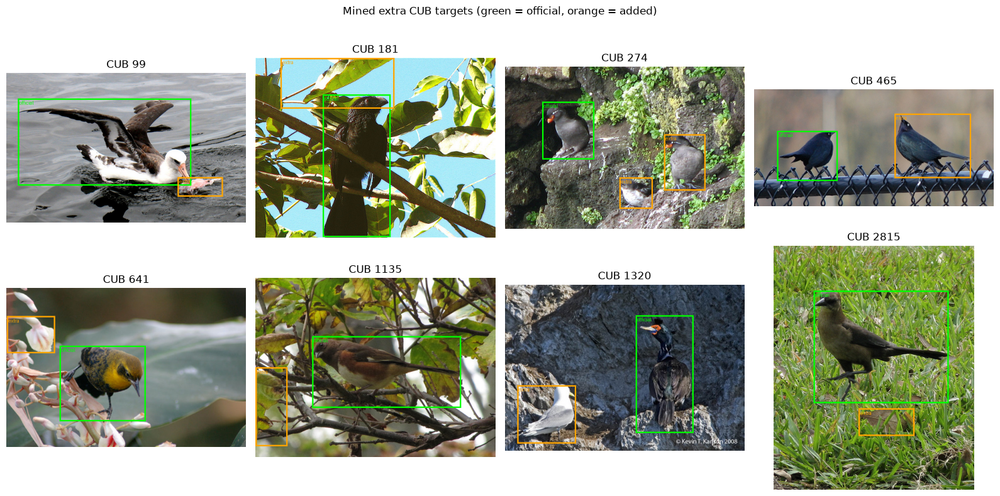

In [12]:
mining_weights = (
    "coco_pretrained"
    if CUB_EXTRA_MINING_CHECKPOINT is None
    else sha256_file(translate_stored_path(CUB_EXTRA_MINING_CHECKPOINT))
)
mining_payload = {
    "model": MODEL_NAME,
    "weights": mining_weights,
    "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
    "train_image_ids": sorted(int(value) for value in cub_splits["train"]["image_id"]),
    "min_score": CUB_EXTRA_MIN_SCORE,
    "max_iou": CUB_EXTRA_MAX_IOU_WITH_TRUTH,
    "max_overlap_fraction": CUB_EXTRA_MAX_OVERLAP_FRACTION,
    "min_short_side": MIN_BOX_SHORT_SIDE_PX,
    "nms": NMS_IOU_THRESHOLD,
    "exif_transpose": APPLY_EXIF_TRANSPOSE,
}
mining_signature = short_hash(mining_payload)
CUB_EXTRA_TARGETS_CSV = BBOX_OUTPUT_DIR / f"cub_extra_targets_{mining_signature}.csv"
extra_columns = ["image_id", "x1", "y1", "x2", "y2", "score", "iou_with_truth"]


def mine_cub_extra_targets(frame: pd.DataFrame) -> pd.DataFrame:
    miner = build_detector().to(DEVICE)
    if CUB_EXTRA_MINING_CHECKPOINT is not None:
        mining_checkpoint = torch.load(
            translate_stored_path(CUB_EXTRA_MINING_CHECKPOINT), map_location=DEVICE, weights_only=False
        )
        miner.load_state_dict(mining_checkpoint["model_state"])
    rows: list[dict[str, Any]] = []
    started = time.perf_counter()
    for position, output, width, height in detector_outputs(miner, frame["_path"].tolist()):
        row = frame.iloc[position]
        scale_x = width / float(row["width_px"])
        scale_y = height / float(row["height_px"])
        truth = torch.tensor(
            [[row["_x1"] * scale_x, row["_y1"] * scale_y, row["_x2"] * scale_x, row["_y2"] * scale_y]],
            dtype=torch.float32,
        )
        boxes, scores, _ = bird_candidates(output, width, height)
        if len(boxes):
            short_side = torch.minimum(boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1])
            keep = (scores >= CUB_EXTRA_MIN_SCORE) & (short_side >= MIN_BOX_SHORT_SIDE_PX)
            boxes, scores = boxes[keep], scores[keep]
        if len(boxes):
            iou = box_iou(boxes, truth)[:, 0]
            intersection = box_intersection(boxes, truth)[:, 0]
            box_area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
            truth_area = (truth[0, 2] - truth[0, 0]) * (truth[0, 3] - truth[0, 1])
            separate = (
                (iou < CUB_EXTRA_MAX_IOU_WITH_TRUTH)
                & (intersection / box_area < CUB_EXTRA_MAX_OVERLAP_FRACTION)
                & (intersection / truth_area < CUB_EXTRA_MAX_OVERLAP_FRACTION)
            )
            for box, score, overlap in zip(boxes[separate], scores[separate], iou[separate]):
                rows.append(
                    {
                        "image_id": int(row["image_id"]),
                        # Stored in manifest coordinates, like the official box.
                        "x1": float(box[0]) / scale_x,
                        "y1": float(box[1]) / scale_y,
                        "x2": float(box[2]) / scale_x,
                        "y2": float(box[3]) / scale_y,
                        "score": float(score),
                        "iou_with_truth": float(overlap),
                    }
                )
        done = position + 1
        if done % 1000 == 0 or done == len(frame):
            rate = done / max(time.perf_counter() - started, 1e-9)
            print(f"  mined {done:,}/{len(frame):,} CUB images | {rate:.1f} images/s", flush=True)
    del miner
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return pd.DataFrame(rows, columns=extra_columns)


if not MINE_CUB_EXTRA_TARGETS:
    cub_extra_targets = pd.DataFrame(columns=extra_columns)
    print("MINE_CUB_EXTRA_TARGETS=False; CUB keeps one target per image")
elif CUB_EXTRA_TARGETS_CSV.is_file():
    cub_extra_targets = pd.read_csv(CUB_EXTRA_TARGETS_CSV)
    print(f"Loaded cached extra targets: {CUB_EXTRA_TARGETS_CSV.name}")
elif not RUN_TRAINING:
    cub_extra_targets = pd.DataFrame(columns=extra_columns)
    print("RUN_TRAINING=False; extra targets are only needed for training, skipping mining")
else:
    print(f"Mining extra CUB targets with {MODEL_NAME} ({mining_weights})")
    cub_extra_targets = mine_cub_extra_targets(cub_splits["train"])
    cub_extra_targets.to_csv(CUB_EXTRA_TARGETS_CSV, index=False)
    print(f"Saved: {CUB_EXTRA_TARGETS_CSV}")

cub_extra_by_image: dict[int, list[list[float]]] = {
    int(image_id): group[["x1", "y1", "x2", "y2"]].to_numpy(dtype=float).tolist()
    for image_id, group in cub_extra_targets.groupby("image_id")
}
print(
    f"Extra CUB targets: {len(cub_extra_targets):,} boxes on "
    f"{len(cub_extra_by_image):,} of {len(cub_splits['train']):,} training images"
)

if len(cub_extra_by_image):
    preview_ids = list(cub_extra_by_image)[:8]
    preview_rows = cub_splits["train"].set_index("image_id").loc[preview_ids]
    columns = 4
    fig, axes = plt.subplots(math.ceil(len(preview_ids) / columns), columns,
                             figsize=(16, 4 * math.ceil(len(preview_ids) / columns)), squeeze=False)
    for ax, (image_id, row) in zip(axes.ravel(), preview_rows.iterrows()):
        image = open_rgb(row["_path"])
        scale_x, scale_y = image.width / row["width_px"], image.height / row["height_px"]
        draw = ImageDraw.Draw(image)
        draw_box(draw, [row["_x1"] * scale_x, row["_y1"] * scale_y, row["_x2"] * scale_x, row["_y2"] * scale_y],
                 "lime", "official")
        for box in cub_extra_by_image[int(image_id)]:
            draw_box(draw, [box[0] * scale_x, box[1] * scale_y, box[2] * scale_x, box[3] * scale_y],
                     "orange", "extra")
        ax.imshow(image)
        ax.set_title(f"CUB {image_id}")
        ax.axis("off")
    for ax in axes.ravel()[len(preview_ids):]:
        ax.axis("off")
    plt.suptitle("Mined extra CUB targets (green = official, orange = added)")
    plt.tight_layout()
    plt.show()

### 4c. Datasets, augmentation, and oversampling

**Augmentation** (training only). Each sample gets:

* a random crop (probability `AUGMENT_CROP_PROBABILITY`) that always contains every box
  whole, so no target is cut in half, and is at least `AUGMENT_MIN_CROP_FRACTION` of each
  side
* a horizontal flip (probability 0.5)
* colour jitter (probability `AUGMENT_COLOR_JITTER_PROBABILITY`)

Scale jitter comes from the model's multi-scale resize. Each batch gets a random shorter
side from `train_min_sizes`.

**Oversampling.** CUB training images and `gt_train` iNaturalist images are combined.
A `WeightedRandomSampler` (with replacement) gives the iNaturalist images about
`INAT_EPOCH_FRACTION` of each epoch. The epoch length is set so CUB is still seen about
once per epoch. The imbalance between single-bird and multi-bird images is left as is,
because single-bird shots really are more common.

`gt_train` `no_bird` images are included with empty targets as pure negatives.

Training mix: 5,194 CUB + 100 iNaturalist GT images | 6,925 samples/epoch | target iNat share 25% | each iNat image seen ~17.3x per epoch
Dataset smoke test passed: torch.Size([3, 326, 407]) [[14.0, 42.0, 301.0, 294.0]]


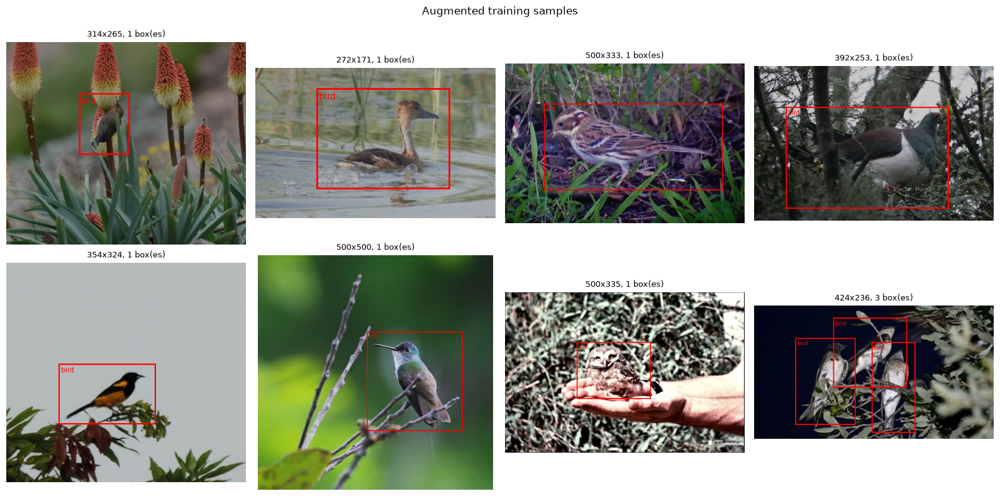

In [13]:
color_jitter = ColorJitter(**COLOR_JITTER_SETTINGS)


def random_int(low: int, high: int) -> int:
    """Uniform integer in [low, high]."""
    low, high = int(low), int(high)
    if high <= low:
        return low
    return int(torch.randint(low, high + 1, ()).item())


def sample_crop_span(size: int, keep_low: float, keep_high: float, min_span: int) -> tuple[int, int]:
    """Return [start, end) that contains [keep_low, keep_high] and is at least min_span long."""
    keep_low_px = max(0, min(size, int(math.floor(keep_low))))
    keep_high_px = max(keep_low_px, min(size, int(math.ceil(keep_high))))
    min_span = min(min_span, size)
    for _ in range(10):
        start = random_int(0, keep_low_px)
        end = random_int(keep_high_px, size)
        if end - start >= min_span:
            return start, end
    return 0, size


def random_box_preserving_crop(image: torch.Tensor, boxes: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    _, height, width = image.shape
    min_width = int(math.ceil(width * AUGMENT_MIN_CROP_FRACTION))
    min_height = int(math.ceil(height * AUGMENT_MIN_CROP_FRACTION))
    if len(boxes):
        left, right = sample_crop_span(width, boxes[:, 0].min().item(), boxes[:, 2].max().item(), min_width)
        top, bottom = sample_crop_span(height, boxes[:, 1].min().item(), boxes[:, 3].max().item(), min_height)
    else:
        crop_width, crop_height = random_int(min_width, width), random_int(min_height, height)
        left, top = random_int(0, width - crop_width), random_int(0, height - crop_height)
        right, bottom = left + crop_width, top + crop_height
    image = image[:, top:bottom, left:right]
    boxes = boxes.clone()
    boxes[:, 0::2] = (boxes[:, 0::2] - left).clamp(0, right - left)
    boxes[:, 1::2] = (boxes[:, 1::2] - top).clamp(0, bottom - top)
    return image, boxes


def horizontal_flip(image: torch.Tensor, boxes: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    width = image.shape[2]
    image = torch.flip(image, dims=[2])
    flipped = boxes.clone()
    flipped[:, 0] = width - boxes[:, 2]
    flipped[:, 2] = width - boxes[:, 0]
    return image, flipped


def augment_detection_sample(image: torch.Tensor, boxes: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    if torch.rand(()) < AUGMENT_CROP_PROBABILITY:
        image, boxes = random_box_preserving_crop(image, boxes)
    if torch.rand(()) < 0.5:
        image, boxes = horizontal_flip(image, boxes)
    if torch.rand(()) < AUGMENT_COLOR_JITTER_PROBABILITY:
        image = color_jitter(image)
    return image.clamp(0, 1).contiguous(), boxes


class DetectionTrainingDataset(Dataset):
    """Rows need _path, _boxes (xyxy lists in _ref_width x _ref_height space), _image_key."""

    def __init__(self, frame: pd.DataFrame, training: bool = False):
        self.frame = frame.reset_index(drop=True)
        self.training = training

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        row = self.frame.iloc[index]
        image = open_rgb(row["_path"])
        actual_width, actual_height = image.size
        scale_x = actual_width / float(row["_ref_width"])
        scale_y = actual_height / float(row["_ref_height"])
        boxes = torch.tensor(row["_boxes"], dtype=torch.float32).reshape(-1, 4)
        boxes[:, 0::2] *= scale_x
        boxes[:, 1::2] *= scale_y
        image_tensor = to_image_tensor(image)
        if self.training:
            image_tensor, boxes = augment_detection_sample(image_tensor, boxes)
        target = {
            "boxes": boxes,
            "labels": torch.full((len(boxes),), BIRD_CLASS_ID, dtype=torch.int64),
            "image_id": torch.tensor([int(row["_image_key"])], dtype=torch.int64),
            "area": (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1]),
            "iscrowd": torch.zeros((len(boxes),), dtype=torch.int64),
        }
        return image_tensor, target


def cub_training_frame(frame: pd.DataFrame, extras: dict[int, list[list[float]]]) -> pd.DataFrame:
    result = frame.copy()
    result["_boxes"] = [
        [[row["_x1"], row["_y1"], row["_x2"], row["_y2"]], *extras.get(int(row["image_id"]), [])]
        for _, row in result.iterrows()
    ]
    result["_ref_width"] = result["width_px"]
    result["_ref_height"] = result["height_px"]
    result["_image_key"] = result["image_id"].astype(int)
    return result


def ground_truth_training_frame(images: pd.DataFrame, truth_boxes: pd.DataFrame) -> pd.DataFrame:
    boxes_by_source = {
        source_id: [[x, y, x + w, y + h] for x, y, w, h in group[["x", "y", "w", "h"]].to_numpy(dtype=float)]
        for source_id, group in truth_boxes.groupby("source_id")
    }
    result = images[["source_id", "_path", "model_width", "model_height"]].copy()
    result["_boxes"] = result["source_id"].map(lambda source_id: boxes_by_source.get(source_id, []))
    result["_ref_width"] = result["model_width"]
    result["_ref_height"] = result["model_height"]
    result["_image_key"] = 10_000_000 + np.arange(len(result))
    return result


cub_train_frame = cub_training_frame(cub_splits["train"], cub_extra_by_image)
cub_validation_frame = cub_training_frame(cub_splits["validation"], {})
cub_test_frame = cub_training_frame(cub_splits["test"], {})
gt_train_frame = (
    ground_truth_training_frame(gt_split_images["gt_train"], gt_truth_boxes)
    if USE_GROUND_TRUTH_FOR_TRAINING
    else ground_truth_training_frame(gt_split_images["gt_train"].head(0), gt_truth_boxes)
)

loader_options = dict(
    num_workers=NUM_WORKERS,
    collate_fn=collate_detection_batch,
    pin_memory= False,
)
cub_train_dataset = DetectionTrainingDataset(cub_train_frame, training=True)
if len(gt_train_frame):
    if not 0 < INAT_EPOCH_FRACTION < 1:
        raise ValueError("INAT_EPOCH_FRACTION must be between 0 and 1")
    gt_train_dataset = DetectionTrainingDataset(gt_train_frame, training=True)
    train_dataset = ConcatDataset([cub_train_dataset, gt_train_dataset])
    cub_count, gt_count = len(cub_train_dataset), len(gt_train_dataset)
    sample_weights = torch.cat(
        [
            torch.full((cub_count,), (1 - INAT_EPOCH_FRACTION) / cub_count),
            torch.full((gt_count,), INAT_EPOCH_FRACTION / gt_count),
        ]
    ).double()
    epoch_samples = int(round(cub_count / (1 - INAT_EPOCH_FRACTION)))
    train_sampler = WeightedRandomSampler(
        sample_weights,
        num_samples=epoch_samples,
        replacement=True,
        generator=torch.Generator().manual_seed(SEED),
    )
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler, **loader_options)
    print(
        f"Training mix: {cub_count:,} CUB + {gt_count} iNaturalist GT images | "
        f"{epoch_samples:,} samples/epoch | target iNat share {INAT_EPOCH_FRACTION:.0%} | "
        f"each iNat image seen ~{INAT_EPOCH_FRACTION * epoch_samples / gt_count:.1f}x per epoch"
    )
else:
    gt_train_dataset = None
    train_loader = DataLoader(cub_train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_options)
    print(f"Training on CUB only: {len(cub_train_dataset):,} images")

validation_loader = DataLoader(
    DetectionTrainingDataset(cub_validation_frame), batch_size=INFERENCE_BATCH_SIZE, shuffle=False, **loader_options
)

images, targets = next(iter(train_loader))
assert images[0].shape[0] == 3 and images[0].dtype == torch.float32
assert all(int(label) == BIRD_CLASS_ID for target in targets for label in target["labels"])
for image, target in zip(images, targets):
    if len(target["boxes"]):
        assert (target["boxes"][:, 2] > target["boxes"][:, 0]).all()
        assert (target["boxes"][:, 2] <= image.shape[2] + 1e-3).all()
        assert (target["boxes"][:, 3] <= image.shape[1] + 1e-3).all()
print("Dataset smoke test passed:", images[0].shape, targets[0]["boxes"].tolist())

# Visual check of the augmentation on iNaturalist training images (or CUB if none).
preview_dataset = gt_train_dataset if gt_train_dataset is not None else cub_train_dataset
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.ravel():
    image, target = preview_dataset[random_int(0, len(preview_dataset) - 1)]
    pil_image = Image.fromarray((image.permute(1, 2, 0).numpy() * 255).astype(np.uint8))
    draw = ImageDraw.Draw(pil_image)
    for box in target["boxes"].tolist():
        draw_box(draw, box, "red", "bird", width=2)
    ax.imshow(pil_image)
    ax.set_title(f"{pil_image.width}x{pil_image.height}, {len(target['boxes'])} box(es)", fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training samples")
plt.tight_layout()
plt.show()

## 5. Detector construction, training, and checkpoints

The COCO prediction head is retained so class 16 remains `bird`. Training uses AMP on
CUDA, and BatchNorm statistics are frozen because a batch of 2 is too small to estimate
them. This matters for `resnet50_fpn_v2`, which uses ordinary BatchNorm. The MobileNet
detectors already use frozen BatchNorm.

After every epoch the model is scored on the held-out `gt_select` images, using the
full policy at the lowest score floor so AP covers the whole ranking. The best
checkpoint is the one with the highest **held-out AP@0.5**. CUB validation loss and
`gt_train` AP are logged next to it. A widening gap between `gt_train` and `gt_select`
AP is the overfitting signal.

Checkpoint files are named per model. Resuming is refused if the training setup
(ground-truth training images, extra targets, sampling, augmentation) has changed.
Loading a checkpoint is refused if any image it was trained on is now in a held-out split.

In [14]:
CHECKPOINT_PREFIX = f"bird_detector_{MODEL_NAME}"
LATEST_CHECKPOINT = CHECKPOINT_DIR / f"{CHECKPOINT_PREFIX}_latest.pt"
BEST_CHECKPOINT = CHECKPOINT_DIR / f"{CHECKPOINT_PREFIX}_best.pt"
TRAINING_HISTORY_CSV = BBOX_OUTPUT_DIR / f"{CHECKPOINT_PREFIX}_training_history.csv"

ground_truth_train_ids = sorted(gt_train_frame["source_id"].tolist())
training_signature = short_hash(
    {
        "model": MODEL_NAME,
        "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
        "cub_train_limit": CUB_TRAIN_LIMIT,
        "ground_truth_train_ids": ground_truth_train_ids,
        "cub_extra_targets": mining_signature if MINE_CUB_EXTRA_TARGETS else None,
        "inat_epoch_fraction": INAT_EPOCH_FRACTION,
        "augmentation": {
            "crop_probability": AUGMENT_CROP_PROBABILITY,
            "min_crop_fraction": AUGMENT_MIN_CROP_FRACTION,
            "color_jitter_probability": AUGMENT_COLOR_JITTER_PROBABILITY,
            "color_jitter": COLOR_JITTER_SETTINGS,
            "train_min_sizes": DETECTOR_REGISTRY[MODEL_NAME]["train_min_sizes"],
        },
        "exif_transpose": APPLY_EXIF_TRANSPOSE,
        "seed": SEED,
    }
)
held_out_ids = set(gt_split_images["gt_select"]["source_id"]) | set(gt_split_images["gt_test"]["source_id"])

has_selection_ground_truth = len(gt_split_images["gt_select"]) > 0
selection_metric = CHECKPOINT_SELECTION_METRIC
if selection_metric == "inat_gt_ap50" and not has_selection_ground_truth:
    print("WARNING: no held-out ground truth; selecting checkpoints on CUB validation loss")
    selection_metric = "cub_validation_loss"
if selection_metric not in ("inat_gt_ap50", "cub_validation_loss"):
    raise ValueError(f"Unknown CHECKPOINT_SELECTION_METRIC={CHECKPOINT_SELECTION_METRIC!r}")

model = build_detector().to(DEVICE)
trainable_parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(
    trainable_parameters,
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=LR_GAMMA)
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

history: list[dict[str, Any]] = []
start_epoch = 0
best_selection_score = -math.inf

if RUN_TRAINING and RESUME_TRAINING and LATEST_CHECKPOINT.is_file():
    checkpoint = torch.load(LATEST_CHECKPOINT, map_location=DEVICE, weights_only=False)
    if checkpoint.get("training_signature") != training_signature:
        raise ValueError(
            f"{LATEST_CHECKPOINT.name} was trained with a different setup (ground-truth "
            "training images, extra targets, sampling or augmentation changed). Delete it, "
            "or set RESUME_TRAINING=False to start a fresh run that overwrites it."
        )
    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    if "scaler_state" in checkpoint:
        scaler.load_state_dict(checkpoint["scaler_state"])
    start_epoch = int(checkpoint["epoch"]) + 1
    history = list(checkpoint.get("history", []))
    best_selection_score = float(checkpoint.get("best_selection_score", -math.inf))
    print(f"Resumed at epoch {start_epoch + 1} from {LATEST_CHECKPOINT}")


def atomic_torch_save(payload: dict[str, Any], destination: Path) -> None:
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    torch.save(payload, temporary)
    temporary.replace(destination)


def move_targets(targets: Sequence[dict[str, torch.Tensor]]) -> list[dict[str, torch.Tensor]]:
    return [{key: value.to(DEVICE) for key, value in target.items()} for target in targets]


def loss_on_loader(loader: DataLoader) -> float:
    # torchvision detectors expose losses only in training mode. No gradients or
    # optimizer updates occur here; BatchNorm statistics are frozen explicitly.
    model.train()
    freeze_batchnorm_statistics(model)
    losses = []
    with torch.no_grad():
        for images, targets in loader:
            images = [image.to(DEVICE, non_blocking=True) for image in images]
            loss_dict = model(images, move_targets(targets))
            losses.append(float(sum(loss_dict.values()).item()))
    return float(np.mean(losses)) if losses else math.nan


def train_one_epoch(loader: DataLoader) -> dict[str, float]:
    model.train()
    if FREEZE_BATCHNORM_STATISTICS:
        freeze_batchnorm_statistics(model)
    totals: Counter[str] = Counter()
    batches = 0
    started = time.perf_counter()
    for batch_index, (images, targets) in enumerate(loader, start=1):
        images = [image.to(DEVICE, non_blocking=True) for image in images]
        targets = move_targets(targets)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
            loss_dict = model(images, targets)
            loss = sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Non-finite training loss: {loss_dict}")
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable_parameters, GRADIENT_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        totals.update({name: float(value.detach().item()) for name, value in loss_dict.items()})
        totals["total_loss"] += float(loss.detach().item())
        batches += 1
        if batch_index % 100 == 0 or batch_index == len(loader):
            print(
                f"  batch {batch_index:>4}/{len(loader)} | "
                f"loss {totals['total_loss'] / batches:.4f}",
                flush=True,
            )
    metrics = {name: value / batches for name, value in totals.items()}
    metrics["minutes"] = (time.perf_counter() - started) / 60
    return metrics


def ground_truth_ap(split_name: str) -> float:
    """Held-out AP@0.5 after the full policy at the lowest score floor."""
    images = gt_split_images[split_name]
    if images.empty:
        return math.nan
    cache = ground_truth_candidates(model, images)
    metrics, _, _ = evaluate_cached_split(cache, images, gt_truth_boxes, MIN_EVALUATION_SCORE)
    return metrics["average_precision_iou_50"]

Resumed at epoch 2 from /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/checkpoints/bird_detector_fasterrcnn_resnet50_fpn_v2_latest.pt


Epoch 2/8 | lr=0.0025
  batch  100/3463 | loss 0.0570
  batch  200/3463 | loss 0.0536
  batch  300/3463 | loss 0.0539
  batch  400/3463 | loss 0.0553
  batch  500/3463 | loss 0.0544
  batch  600/3463 | loss 0.0537
  batch  700/3463 | loss 0.0523
  batch  800/3463 | loss 0.0527
  batch  900/3463 | loss 0.0517
  batch 1000/3463 | loss 0.0514
  batch 1100/3463 | loss 0.0521
  batch 1200/3463 | loss 0.0519
  batch 1300/3463 | loss 0.0518
  batch 1400/3463 | loss 0.0514
  batch 1500/3463 | loss 0.0517
  batch 1600/3463 | loss 0.0516
  batch 1700/3463 | loss 0.0513
  batch 1800/3463 | loss 0.0511
  batch 1900/3463 | loss 0.0509
  batch 2000/3463 | loss 0.0507
  batch 2100/3463 | loss 0.0508
  batch 2200/3463 | loss 0.0503
  batch 2300/3463 | loss 0.0500
  batch 2400/3463 | loss 0.0500
  batch 2500/3463 | loss 0.0498
  batch 2600/3463 | loss 0.0498
  batch 2700/3463 | loss 0.0497
  batch 2800/3463 | loss 0.0495
  batch 2900/3463 | loss 0.0492
  batch 3000/3463 | loss 0.0489
  batch 3100/3463 

[W1017 10:23:02.621581426 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 444596224 bytes (free: 0, total: 6441926656).


  train=0.0490 | CUB val loss=0.0442 | gt_select AP50=0.7935 | gt_train AP50=0.9909 | best=False
Epoch 3/8 | lr=0.0025
  batch  100/3463 | loss 0.0452
  batch  200/3463 | loss 0.0470
  batch  300/3463 | loss 0.0449
  batch  400/3463 | loss 0.0470
  batch  500/3463 | loss 0.0476
  batch  600/3463 | loss 0.0473
  batch  700/3463 | loss 0.0466
  batch  800/3463 | loss 0.0466
  batch  900/3463 | loss 0.0465
  batch 1000/3463 | loss 0.0458
  batch 1100/3463 | loss 0.0460
  batch 1200/3463 | loss 0.0456
  batch 1300/3463 | loss 0.0456
  batch 1400/3463 | loss 0.0458
  batch 1500/3463 | loss 0.0458
  batch 1600/3463 | loss 0.0454
  batch 1700/3463 | loss 0.0455
  batch 1800/3463 | loss 0.0458
  batch 1900/3463 | loss 0.0457
  batch 2000/3463 | loss 0.0454
  batch 2100/3463 | loss 0.0456
  batch 2200/3463 | loss 0.0454
  batch 2300/3463 | loss 0.0454
  batch 2400/3463 | loss 0.0451
  batch 2500/3463 | loss 0.0450
  batch 2600/3463 | loss 0.0450
  batch 2700/3463 | loss 0.0451
  batch 2800/3463

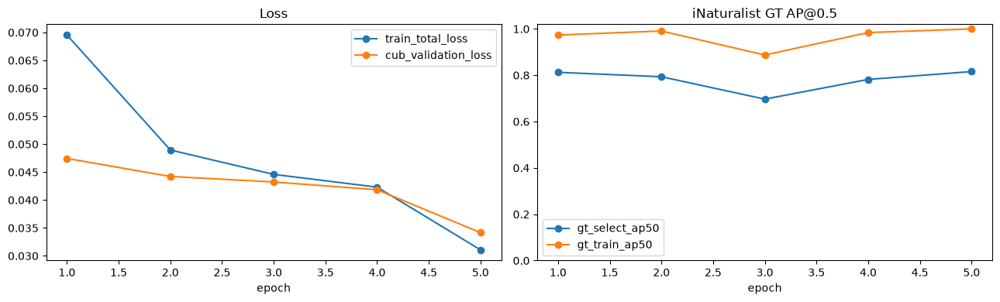

In [15]:
if RUN_TRAINING:
    for epoch in range(start_epoch, EPOCHS):
        print(f"Epoch {epoch + 1}/{EPOCHS} | lr={optimizer.param_groups[0]['lr']:.6g}")
        train_metrics = train_one_epoch(train_loader)
        validation_loss = loss_on_loader(validation_loader)
        select_ap = ground_truth_ap("gt_select")
        train_ap = ground_truth_ap("gt_train")
        scheduler.step()
        row = {
            "epoch": epoch + 1,
            **{f"train_{key}": value for key, value in train_metrics.items()},
            "cub_validation_loss": validation_loss,
            "gt_select_ap50": select_ap,
            "gt_train_ap50": train_ap,
            "learning_rate": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        score = select_ap if selection_metric == "inat_gt_ap50" else -validation_loss
        improved = score > best_selection_score
        if improved:
            best_selection_score = score
        payload = {
            "epoch": epoch,
            "model_name": MODEL_NAME,
            "bird_class_id": BIRD_CLASS_ID,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(),
            "history": history,
            "selection_metric": selection_metric,
            "best_selection_score": best_selection_score,
            "training_signature": training_signature,
            "ground_truth_train_ids": ground_truth_train_ids,
            "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
            "created_utc": utc_now(),
        }
        atomic_torch_save(payload, LATEST_CHECKPOINT)
        if improved:
            atomic_torch_save(payload, BEST_CHECKPOINT)
        pd.DataFrame(history).to_csv(TRAINING_HISTORY_CSV, index=False)
        print(
            f"  train={train_metrics['total_loss']:.4f} | CUB val loss={validation_loss:.4f} | "
            f"gt_select AP50={select_ap:.4f} | gt_train AP50={train_ap:.4f} | best={improved}"
        )
else:
    print("RUN_TRAINING=False; using an existing checkpoint")

checkpoint_to_load = BEST_CHECKPOINT if BEST_CHECKPOINT.is_file() else LATEST_CHECKPOINT
if not checkpoint_to_load.is_file():
    raise FileNotFoundError(
        f"No trained {MODEL_NAME} checkpoint exists. Set RUN_TRAINING=True and run this cell."
    )
checkpoint = torch.load(checkpoint_to_load, map_location=DEVICE, weights_only=False)
if checkpoint.get("model_name") != MODEL_NAME:
    raise ValueError(f"{checkpoint_to_load.name} is a {checkpoint.get('model_name')} checkpoint")
if checkpoint.get("cub_manifest_sha256") != sha256_file(CUB_MANIFEST):
    raise ValueError("Checkpoint was trained from a different CUB manifest")
leaked = sorted(set(checkpoint.get("ground_truth_train_ids", [])) & held_out_ids)
if leaked:
    raise ValueError(
        f"{len(leaked)} images this checkpoint trained on are now held out (e.g. {leaked[:3]}). "
        "Restore the original split file or retrain."
    )
model.load_state_dict(checkpoint["model_state"])
model.eval()
history = list(checkpoint.get("history", history))
print(
    f"Loaded detector: {checkpoint_to_load} (epoch {int(checkpoint['epoch']) + 1}, "
    f"selected on {checkpoint.get('selection_metric')})"
)

if history:
    history_frame = pd.DataFrame(history).set_index("epoch")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    history_frame[["train_total_loss", "cub_validation_loss"]].plot(ax=axes[0], marker="o", title="Loss")
    history_frame[["gt_select_ap50", "gt_train_ap50"]].plot(ax=axes[1], marker="o", title="iNaturalist GT AP@0.5")
    axes[1].set_ylim(0, 1.02)
    plt.tight_layout()
    plt.show()

## 6. CUB localisation sanity check

CUB is reported for sanity only and **does not choose any threshold**. Every CUB image
contains a bird, so there are no negatives, and recall is flat across almost every
threshold. In v1 the rule "highest threshold within one point of the best recall" was
therefore always picking the top of the grid (0.95), and that value was never used.

`multiple_bird_rate_after_nms` is now computed on the post-NMS candidates at each
threshold. In v1 it counted raw outputs with internal NMS disabled, so it was always 1.0.
Most CUB photos contain one bird, so this rate roughly tracks duplicate and
false-positive boxes. The extra targets mean some second boxes are real birds.

,threshold,images,detections,detection_rate,mean_iou_all_images,median_iou_detected,recall_iou_50,recall_iou_75,multiple_bird_rate_after_nms
0,0.050,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.20250
1,0.075,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.16375
2,0.100,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.15000
3,0.125,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.13500
4,0.150,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.12250
5,0.175,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.11125
6,0.200,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.10625
7,0.225,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.10250
8,0.250,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.09250
9,0.275,800,800,1.00000,0.919960,0.940099,0.99500,0.97375,0.08750


,threshold,images,detections,detection_rate,mean_iou_all_images,median_iou_detected,recall_iou_50,recall_iou_75,multiple_bird_rate_after_nms
split,,,,,,,,,
validation,0.5,800,800,1.000000,0.919960,0.940099,0.995000,0.973750,0.045000
test,0.5,5794,5788,0.998964,0.914261,0.936405,0.994477,0.961512,0.040387


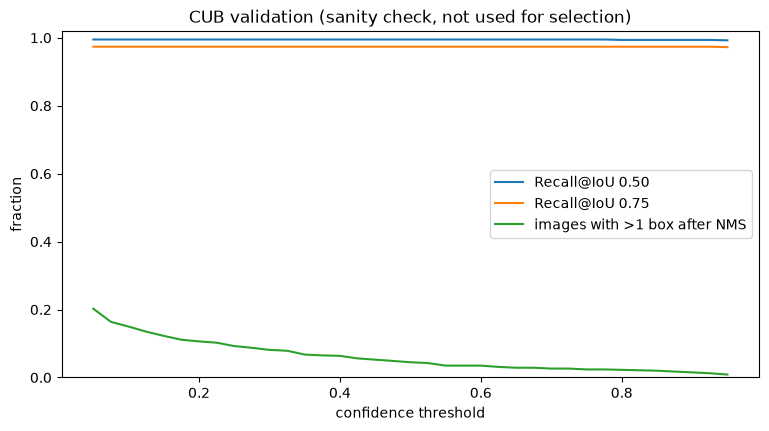

In [16]:
def predict_cub_split(frame: pd.DataFrame) -> pd.DataFrame:
    records: list[dict[str, Any]] = []
    for position, output, width, height in detector_outputs(model, frame["_path"].tolist()):
        row = frame.iloc[position]
        scale_x, scale_y = width / float(row["width_px"]), height / float(row["height_px"])
        truth = [row["_x1"] * scale_x, row["_y1"] * scale_y, row["_x2"] * scale_x, row["_y2"] * scale_y]
        boxes, scores, _ = bird_candidates(output, width, height)
        if len(scores):
            top = int(torch.argmax(scores).item())
            score, box = float(scores[top].item()), boxes[top].tolist()
        else:
            score, box = np.nan, None
        records.append(
            {
                "image_id": int(row["image_id"]),
                "class_id": int(row["class_id"]),
                "path": row["_path"],
                "score": score,
                "predicted_box": box,
                "ground_truth_box": truth,
                "iou_if_detected": box_iou_one(box, truth),
                "post_nms_scores": scores.tolist(),
                "image_width": width,
                "image_height": height,
            }
        )
    return pd.DataFrame(records)


def metrics_at_threshold(predictions: pd.DataFrame, threshold: float) -> dict[str, Any]:
    accepted = predictions["score"].fillna(-1).ge(threshold)
    effective_iou = predictions["iou_if_detected"].where(accepted, 0.0)
    detected_iou = predictions.loc[accepted, "iou_if_detected"]
    boxes_kept = predictions["post_nms_scores"].map(lambda scores: sum(s >= threshold for s in scores))
    return {
        "threshold": float(threshold),
        "images": int(len(predictions)),
        "detections": int(accepted.sum()),
        "detection_rate": float(accepted.mean()),
        "mean_iou_all_images": float(effective_iou.mean()),
        "median_iou_detected": float(detected_iou.median()) if len(detected_iou) else 0.0,
        "recall_iou_50": float(effective_iou.ge(0.50).mean()),
        "recall_iou_75": float(effective_iou.ge(0.75).mean()),
        "multiple_bird_rate_after_nms": float(boxes_kept.gt(1).mean()),
    }


validation_predictions = predict_cub_split(cub_splits["validation"])
cub_threshold_metrics = pd.DataFrame(
    [metrics_at_threshold(validation_predictions, threshold) for threshold in THRESHOLD_GRID]
)
cub_threshold_metrics.to_csv(BBOX_OUTPUT_DIR / "cub_validation_threshold_metrics.csv", index=False)
display(cub_threshold_metrics)

test_predictions = predict_cub_split(cub_splits["test"])
cub_metrics = pd.DataFrame(
    [
        {"split": "validation", **metrics_at_threshold(validation_predictions, CUB_REPORT_THRESHOLD)},
        {"split": "test", **metrics_at_threshold(test_predictions, CUB_REPORT_THRESHOLD)},
    ]
)
cub_metrics.to_csv(BBOX_OUTPUT_DIR / "cub_bird_detector_metrics.csv", index=False)
display(cub_metrics.set_index("split"))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(cub_threshold_metrics["threshold"], cub_threshold_metrics["recall_iou_50"], label="Recall@IoU 0.50")
ax.plot(cub_threshold_metrics["threshold"], cub_threshold_metrics["recall_iou_75"], label="Recall@IoU 0.75")
ax.plot(cub_threshold_metrics["threshold"], cub_threshold_metrics["multiple_bird_rate_after_nms"],
        label="images with >1 box after NMS")
ax.set(xlabel="confidence threshold", ylabel="fraction", ylim=(0, 1.02),
       title="CUB validation (sanity check, not used for selection)")
ax.legend()
plt.show()

if cub_metrics.set_index("split").loc["test", "recall_iou_50"] < 0.50:
    print(
        "WARNING: CUB test Recall@IoU 0.50 is below 50%. Review training and QA "
        "before treating iNaturalist predictions as usable pseudo-labels."
    )

Lowest-IoU accepted CUB test predictions (green=ground truth, red=prediction)


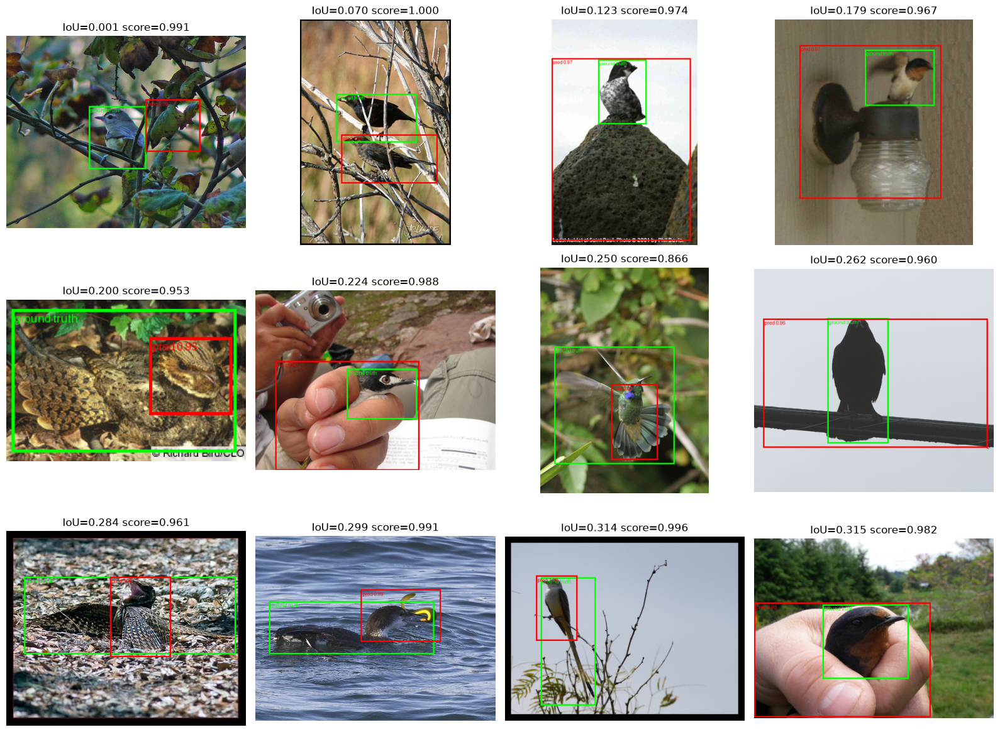

In [17]:
def show_cub_predictions(predictions: pd.DataFrame, count: int = 12, sort_by: str | None = None) -> None:
    shown = predictions.copy()
    if sort_by is not None:
        shown = shown.sort_values(sort_by)
    shown = shown.head(min(count, len(shown)))
    if shown.empty:
        print("No CUB predictions to show")
        return
    columns = 4
    rows = math.ceil(len(shown) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(16, 4 * rows), squeeze=False)
    for ax, (_, row) in zip(axes.ravel(), shown.iterrows()):
        image = open_rgb(row["path"])
        draw = ImageDraw.Draw(image)
        draw_box(draw, row["ground_truth_box"], "lime", "ground truth")
        if pd.notna(row["score"]) and float(row["score"]) >= CUB_REPORT_THRESHOLD:
            draw_box(draw, row["predicted_box"], "red", f"pred {row['score']:.2f}")
        ax.imshow(image)
        ax.set_title(f"IoU={row['iou_if_detected']:.3f} score={row['score']:.3f}")
        ax.axis("off")
    for ax in axes.ravel()[len(shown):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


print("Lowest-IoU accepted CUB test predictions (green=ground truth, red=prediction)")
accepted_test = test_predictions.loc[test_predictions["score"].fillna(-1).ge(CUB_REPORT_THRESHOLD)]
show_cub_predictions(accepted_test, count=12, sort_by="iou_if_detected")

### 6b. iNaturalist confidence threshold from the held-out precision-recall curve

The detector is run once over every scored ground-truth image, and the post-NMS
candidates are cached. The full retention policy (score, size, confident-only mixed-size
rule) is then re-applied at each threshold in `THRESHOLD_GRID`, and the result is scored
against the `gt_select` boxes.

The threshold is chosen by `THRESHOLD_SELECTION_RULE`:

* `max_f1` is the default. Ties go to the higher threshold.
* `min_precision` takes the highest recall with precision ≥ `TARGET_PRECISION`. Use this
  if false-positive boxes hurt the downstream classifier more than missed birds do.

`MANUAL_CONFIDENCE_THRESHOLD` overrides both. The selected value becomes
`DETECTION_SCORE_THRESHOLD` and **is the threshold used for inference in section 7**.
The v1 value of 0.05 is shown for comparison. It kept about 16k more boxes than one per
image across 69,805 images, and many of the extras were likely false positives.

,threshold,precision,recall,f1,true_positives,false_positives,predictions,images_with_multiple_predictions,selected
0,0.050,0.711111,0.827586,0.764940,96,39,135,25,False
1,0.075,0.730769,0.818966,0.772358,95,35,130,23,False
2,0.100,0.752000,0.810345,0.780083,94,31,125,20,False
3,0.125,0.764228,0.810345,0.786611,94,29,123,20,False
4,0.150,0.770492,0.810345,0.789916,94,28,122,19,False
5,0.175,0.776860,0.810345,0.793249,94,27,121,19,False
6,0.200,0.783333,0.810345,0.796610,94,26,120,19,False
7,0.225,0.788136,0.801724,0.794872,93,25,118,19,False
8,0.250,0.788136,0.801724,0.794872,93,25,118,19,False
9,0.275,0.798246,0.784483,0.791304,91,23,114,17,False


Selected iNaturalist confidence threshold: 0.800 (max_f1 on gt_select (97 images))


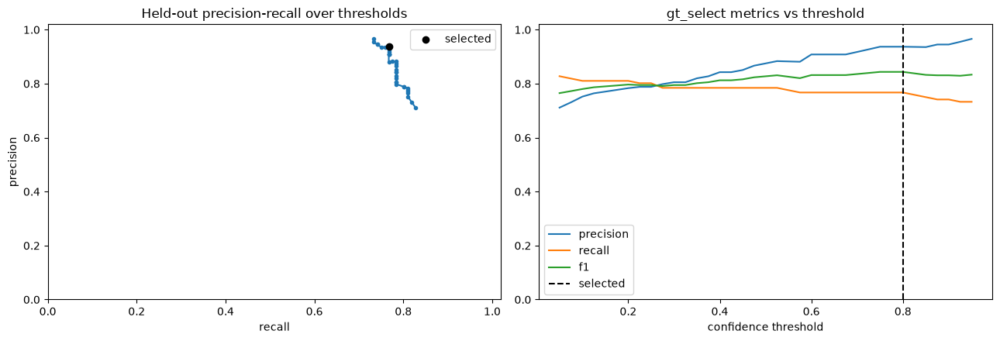

,split,policy,threshold,images,precision,recall,f1,ap50_full_ranking,note
0,gt_train,selected,0.80,100,1.000000,0.992063,0.996016,0.999938,"trained on: memorised, not a quality estimate"
1,gt_train,v1 (0.05),0.05,100,0.913043,1.000000,0.954545,0.999938,"trained on: memorised, not a quality estimate"
2,gt_select,selected,0.80,97,0.936842,0.767241,0.843602,0.816309,held out from training; chose checkpoint + thr...
3,gt_select,v1 (0.05),0.05,97,0.711111,0.827586,0.764940,0.816309,held out from training; chose checkpoint + thr...


In [18]:
ground_truth_cache = ground_truth_candidates(model, gt_scored_images)
for record in gt_scored_images.to_dict(orient="records"):
    entry = ground_truth_cache[record["source_id"]]
    if (entry["width"], entry["height"]) != (record["model_width"], record["model_height"]):
        raise AssertionError(f"Detector image size differs from section 3b for {record['source_id']}")

selection_images = gt_split_images["gt_select"]
sweep_rows = []
if not selection_images.empty:
    for threshold in THRESHOLD_GRID:
        metrics, _, _ = evaluate_cached_split(ground_truth_cache, selection_images, gt_truth_boxes, float(threshold))
        sweep_rows.append(
            {
                "threshold": float(threshold),
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1"],
                "true_positives": metrics["true_positives"],
                "false_positives": metrics["false_positives"],
                "predictions": metrics["evaluated_predictions"],
                "images_with_multiple_predictions": metrics["images_with_multiple_predictions"],
            }
        )
threshold_sweep = pd.DataFrame(sweep_rows)

if MANUAL_CONFIDENCE_THRESHOLD is not None:
    selected_threshold, selection_reason = float(MANUAL_CONFIDENCE_THRESHOLD), "manual override"
elif threshold_sweep.empty:
    raise ValueError("No held-out ground truth is available; set MANUAL_CONFIDENCE_THRESHOLD")
else:
    rule = THRESHOLD_SELECTION_RULE
    eligible = threshold_sweep
    if rule == "min_precision":
        eligible = threshold_sweep.loc[threshold_sweep["precision"].ge(TARGET_PRECISION)]
        if eligible.empty:
            print(f"WARNING: no threshold reaches precision {TARGET_PRECISION:.2f}; falling back to max_f1")
            rule = "max_f1"
            eligible = threshold_sweep
        else:
            chosen = eligible.sort_values(["recall", "threshold"], ascending=[False, False]).iloc[0]
    if rule == "max_f1":
        chosen = eligible.sort_values(["f1", "threshold"], ascending=[False, False]).iloc[0]
    elif rule != "min_precision":
        raise ValueError(f"Unknown THRESHOLD_SELECTION_RULE={THRESHOLD_SELECTION_RULE!r}")
    selected_threshold = float(chosen["threshold"])
    selection_reason = f"{rule} on gt_select ({len(selection_images)} images)"
if not 0 <= selected_threshold <= 1:
    raise ValueError(f"Invalid confidence threshold: {selected_threshold}")

DETECTION_SCORE_THRESHOLD = selected_threshold
selected_select_metrics = (
    evaluate_cached_split(ground_truth_cache, selection_images, gt_truth_boxes, DETECTION_SCORE_THRESHOLD)[0]
    if not selection_images.empty
    else None
)
threshold_selection = {
    "rule": THRESHOLD_SELECTION_RULE,
    "reason": selection_reason,
    "selected_threshold": DETECTION_SCORE_THRESHOLD,
    "target_precision": TARGET_PRECISION if THRESHOLD_SELECTION_RULE == "min_precision" else None,
    "selection_split": "gt_select",
    "selection_images": int(len(selection_images)),
    "metrics_at_selected_threshold": selected_select_metrics,
}
if not threshold_sweep.empty:
    threshold_sweep.to_csv(BBOX_OUTPUT_DIR / "inaturalist_gt_threshold_sweep.csv", index=False)
    display(threshold_sweep.assign(selected=threshold_sweep["threshold"].eq(DETECTION_SCORE_THRESHOLD)))
print(f"Selected iNaturalist confidence threshold: {DETECTION_SCORE_THRESHOLD:.3f} ({selection_reason})")

if not threshold_sweep.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].plot(threshold_sweep["recall"], threshold_sweep["precision"], marker=".")
    chosen_row = threshold_sweep.loc[threshold_sweep["threshold"].eq(DETECTION_SCORE_THRESHOLD)]
    if len(chosen_row):
        axes[0].scatter(chosen_row["recall"], chosen_row["precision"], color="black", zorder=3, label="selected")
        axes[0].legend()
    axes[0].set(xlabel="recall", ylabel="precision", xlim=(0, 1.02), ylim=(0, 1.02),
                title="Held-out precision-recall over thresholds")
    for column in ("precision", "recall", "f1"):
        axes[1].plot(threshold_sweep["threshold"], threshold_sweep[column], label=column)
    axes[1].axvline(DETECTION_SCORE_THRESHOLD, color="black", linestyle="--", label="selected")
    axes[1].set(xlabel="confidence threshold", ylim=(0, 1.02), title="gt_select metrics vs threshold")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

split_notes = {
    "gt_train": "trained on: memorised, not a quality estimate",
    "gt_select": "held out from training; chose checkpoint + threshold (slightly optimistic)",
    "gt_test": "untouched held-out report set",
}
comparison_rows = []
for split_name, images in gt_split_images.items():
    if images.empty:
        continue
    full_ranking_ap = evaluate_cached_split(
        ground_truth_cache, images, gt_truth_boxes, MIN_EVALUATION_SCORE
    )[0]["average_precision_iou_50"]
    for label, threshold in (("selected", DETECTION_SCORE_THRESHOLD), ("v1 (0.05)", 0.05)):
        metrics, _, _ = evaluate_cached_split(ground_truth_cache, images, gt_truth_boxes, threshold)
        comparison_rows.append(
            {
                "split": split_name,
                "policy": label,
                "threshold": threshold,
                "images": metrics["images"],
                "precision": metrics["precision"],
                "recall": metrics["recall"],
                "f1": metrics["f1"],
                "ap50_full_ranking": full_ranking_ap,
                "note": split_notes[split_name],
            }
        )
display(pd.DataFrame(comparison_rows))

## 7. Resumable multi-box iNaturalist inference

The progress filename includes a run signature derived from the source manifest,
checkpoint, row limit, and every post-processing setting, **including the threshold
selected in 6b**. Each completed image is flushed as one JSON record containing its
retained detections and audit counts. Corrupt or unreadable images become
`image_error` records instead of terminating the full run.

Torchvision normally applies internal class-wise NMS before returning detections.
The model construction relaxes that internal threshold, and the explicit bird-only NMS
in `bird_candidates` is authoritative. Delete a specific progress file only when
intentionally restarting that exact run.

In [19]:
checkpoint_sha256 = sha256_file(checkpoint_to_load)
inat_manifest_sha256 = sha256_file(INAT_MANIFEST)
postprocess_policy = {
    "progress_schema_version": PROGRESS_SCHEMA_VERSION,
    "bird_class_id": BIRD_CLASS_ID,
    "model_output_score_floor": MIN_EVALUATION_SCORE,
    "nms_iou_threshold": NMS_IOU_THRESHOLD,
    "internal_nms_iou_threshold": INTERNAL_NMS_IOU_THRESHOLD,
    "score_threshold": DETECTION_SCORE_THRESHOLD,
    "score_threshold_source": threshold_selection["reason"],
    "minimum_short_side_px": MIN_BOX_SHORT_SIDE_PX,
    "mixed_size_area_ratio": MIXED_SIZE_AREA_RATIO,
    "mixed_rule_min_score": MIXED_RULE_MIN_SCORE,
    "main_bird_priority": "clipped_box_area_times_confidence",
    "raw_detections_per_image": RAW_DETECTIONS_PER_IMAGE,
    "inference_min_size": DETECTOR_REGISTRY[MODEL_NAME]["train_min_sizes"][-1],
    "exif_transpose": APPLY_EXIF_TRANSPOSE,
}
run_signature_payload = {
    "model": MODEL_NAME,
    "checkpoint_sha256": checkpoint_sha256,
    "inaturalist_manifest_sha256": inat_manifest_sha256,
    "limit": INATURALIST_LIMIT,
    "postprocess_policy": postprocess_policy,
}
run_signature = short_hash(run_signature_payload)
PROGRESS_JSONL = BBOX_OUTPUT_DIR / f"inaturalist_multibox_progress_{run_signature}.jsonl"

inat_to_process = inat if INATURALIST_LIMIT is None else inat.head(INATURALIST_LIMIT).copy()


def read_progress(path: Path) -> dict[int, dict[str, Any]]:
    records: dict[int, dict[str, Any]] = {}
    if not path.is_file():
        return records
    with path.open("r", encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            if not line.strip():
                continue
            try:
                record = json.loads(line)
                if int(record["schema_version"]) != PROGRESS_SCHEMA_VERSION:
                    raise ValueError("incompatible progress schema")
                records[int(record["row_index"])] = record
            except (json.JSONDecodeError, KeyError, TypeError, ValueError) as exc:
                # A final partial line can result from an abrupt process termination.
                print(f"Ignoring invalid progress line {line_number}: {exc}")
    return records


def load_image_for_inference(path: str) -> tuple[torch.Tensor, int, int]:
    image = open_rgb(path)
    width, height = image.size
    return to_image_tensor(image), width, height


def prediction_record(
    row: pd.Series,
    output: dict[str, torch.Tensor] | None,
    width: int | None,
    height: int | None,
    error: str | None = None,
) -> dict[str, Any]:
    base: dict[str, Any] = {
        "schema_version": PROGRESS_SCHEMA_VERSION,
        "row_index": int(row["_row_index"]),
        "source_id": str(row["_canonical_source_id"]),
        "source_image_id": str(row["_source_image_id"]),
        "image_width_px": width,
        "image_height_px": height,
        "detections": [],
        "saved_detection_count": 0,
        **AUDIT_DEFAULTS,
        "status": "image_error" if error else "no_qualifying_detection",
        "error": error,
    }
    if error or output is None:
        return base
    if width is None or height is None or width <= 0 or height <= 0:
        raise ValueError("Valid image dimensions are required for post-processing")
    detections, audit = postprocess_bird_detections(output, width, height, DETECTION_SCORE_THRESHOLD)
    base.update(audit)
    base["detections"] = detections
    base["saved_detection_count"] = len(detections)
    base["status"] = "detected" if detections else "no_qualifying_detection"
    return base


if not RESUME_INFERENCE and PROGRESS_JSONL.exists():
    PROGRESS_JSONL.unlink()
completed = read_progress(PROGRESS_JSONL) if RESUME_INFERENCE else {}
expected_source_by_index = dict(
    zip(
        inat_to_process["_row_index"].astype(int),
        inat_to_process["_canonical_source_id"].astype(str),
    )
)
for row_index, record in completed.items():
    if row_index in expected_source_by_index and record.get("source_id") != expected_source_by_index[row_index]:
        raise ValueError(f"Progress source ID mismatch at row {row_index}")
pending = inat_to_process.loc[~inat_to_process["_row_index"].isin(completed)].copy()
print(f"Run signature:     {run_signature}")
print(f"Score threshold:   {DETECTION_SCORE_THRESHOLD:.3f} ({threshold_selection['reason']})")
print(f"Already completed: {len(completed):,}")
print(f"Pending:           {len(pending):,}")
print(f"Progress file:     {PROGRESS_JSONL}")

Run signature:     f21df69e17fdf44b
Score threshold:   0.800 (max_f1 on gt_select (97 images))
Already completed: 0
Pending:           74,300
Progress file:     /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_multibox_progress_f21df69e17fdf44b.jsonl


In [20]:
def append_progress(handle: Any, records: Iterable[dict[str, Any]]) -> None:
    for record in records:
        handle.write(json.dumps(json_safe(record), ensure_ascii=False) + "\n")
    handle.flush()


if RUN_INATURALIST_INFERENCE and len(pending):
    model.eval()
    started = time.perf_counter()
    processed_this_run = 0
    pending_rows = [row for _, row in pending.iterrows()]

    # Ensure an interrupted partial final line cannot consume the first resumed record.
    if PROGRESS_JSONL.is_file() and PROGRESS_JSONL.stat().st_size:
        with PROGRESS_JSONL.open("rb") as existing_handle:
            existing_handle.seek(-1, os.SEEK_END)
            ends_with_newline = existing_handle.read(1) == b"\n"
        if not ends_with_newline:
            with PROGRESS_JSONL.open("ab") as repair_handle:
                repair_handle.write(b"\n")

    with PROGRESS_JSONL.open("a", encoding="utf-8", buffering=1) as progress_handle:
        for batch_start in range(0, len(pending_rows), INFERENCE_BATCH_SIZE):
            batch_rows = pending_rows[batch_start : batch_start + INFERENCE_BATCH_SIZE]
            valid_rows: list[pd.Series] = []
            images: list[torch.Tensor] = []
            dimensions: list[tuple[int, int]] = []

            for row in batch_rows:
                try:
                    image, width, height = load_image_for_inference(row["_path"])
                    images.append(image)
                    dimensions.append((width, height))
                    valid_rows.append(row)
                except Exception as exc:
                    record = prediction_record(
                        row, None, None, None,
                        error=f"{type(exc).__name__}: {exc}",
                    )
                    append_progress(progress_handle, [record])
                    completed[int(row["_row_index"])] = record
                    processed_this_run += 1

            if images:
                try:
                    with torch.inference_mode():
                        outputs = model(
                            [image.to(DEVICE, non_blocking=True) for image in images]
                        )
                    batch_records = []
                    for row, (width, height), output in zip(valid_rows, dimensions, outputs):
                        record = prediction_record(row, output, width, height)
                        batch_records.append(record)
                        completed[int(row["_row_index"])] = record
                    append_progress(progress_handle, batch_records)
                    processed_this_run += len(batch_records)
                except RuntimeError as exc:
                    if DEVICE.type == "cuda":
                        torch.cuda.empty_cache()
                    raise RuntimeError(
                        f"Detector failed at pending batch offset {batch_start}. "
                        "Progress through the previous batch is saved. Reduce "
                        "INFERENCE_BATCH_SIZE if this was an out-of-memory error."
                    ) from exc

            if processed_this_run % 500 < len(batch_rows) or processed_this_run == len(pending_rows):
                elapsed = time.perf_counter() - started
                rate = processed_this_run / elapsed if elapsed else 0.0
                remaining = len(pending_rows) - processed_this_run
                eta_minutes = remaining / rate / 60 if rate else math.inf
                print(
                    f"Processed {processed_this_run:,}/{len(pending_rows):,} this run | "
                    f"{rate:.2f} images/s | ETA {eta_minutes:.1f} min",
                    flush=True,
                )
elif not RUN_INATURALIST_INFERENCE:
    print("RUN_INATURALIST_INFERENCE=False; no new images processed")
else:
    print("Inference is already complete for this run signature")

completed = read_progress(PROGRESS_JSONL)
expected_indices = set(inat_to_process["_row_index"].astype(int))
missing_indices = expected_indices - set(completed)
if RUN_INATURALIST_INFERENCE and missing_indices:
    raise AssertionError(f"Inference ended with {len(missing_indices):,} unprocessed rows")
for row_index in expected_indices & set(completed):
    if completed[row_index].get("source_id") != expected_source_by_index[row_index]:
        raise ValueError(f"Progress source ID mismatch at row {row_index}")
print(f"Progress records available: {len(completed):,}")

Processed 500/74,300 this run | 0.50 images/s | ETA 2460.9 min
Processed 1,000/74,300 this run | 0.50 images/s | ETA 2437.8 min
Processed 1,500/74,300 this run | 0.50 images/s | ETA 2435.0 min
Processed 2,500/74,300 this run | 0.50 images/s | ETA 2415.1 min
Processed 3,000/74,300 this run | 0.49 images/s | ETA 2401.1 min
Processed 3,500/74,300 this run | 0.49 images/s | ETA 2402.3 min
Processed 4,000/74,300 this run | 0.49 images/s | ETA 2398.4 min
Processed 4,500/74,300 this run | 0.48 images/s | ETA 2399.3 min
Processed 5,000/74,300 this run | 0.49 images/s | ETA 2380.7 min
Processed 5,500/74,300 this run | 0.49 images/s | ETA 2363.1 min
Processed 6,000/74,300 this run | 0.49 images/s | ETA 2340.6 min
Processed 6,500/74,300 this run | 0.49 images/s | ETA 2325.8 min
Processed 7,000/74,300 this run | 0.49 images/s | ETA 2311.6 min
Processed 7,500/74,300 this run | 0.49 images/s | ETA 2292.1 min
Processed 8,000/74,300 this run | 0.49 images/s | ETA 2265.2 min
Processed 8,500/74,300 this

## 8. Export one retained detection per row

The primary CSV has exactly `source_id,x,y,w,h,score`, with no placeholder row
for images that have no qualifying box. A separate image-level audit CSV keeps
zero-detection records, image errors, stage counts, and mixed-size decisions, plus
`max_bird_score` and `mixed_rule_candidate_count`, which drive the labelling queue.
CSV files use UTF-8 with a BOM for spreadsheet compatibility.

In [21]:
if not completed:
    raise RuntimeError(
        "No inference records are available. Enable inference or provide a completed "
        "progress file for the current run signature."
    )

prediction_frame = pd.DataFrame(completed.values()).sort_values("row_index", kind="stable")
prediction_frame = prediction_frame.loc[
    prediction_frame["row_index"].isin(expected_indices)
].copy()
if len(prediction_frame) != len(inat_to_process):
    raise AssertionError(
        f"Expected {len(inat_to_process):,} image records, found {len(prediction_frame):,}"
    )
if prediction_frame["row_index"].duplicated().any():
    raise AssertionError("Prediction row indices are not unique")

box_rows: list[dict[str, Any]] = []
for record in prediction_frame.to_dict(orient="records"):
    for detection in record["detections"]:
        box_rows.append(
            {
                "source_id": str(record["source_id"]),
                "x": float(detection["x"]),
                "y": float(detection["y"]),
                "w": float(detection["w"]),
                "h": float(detection["h"]),
                "score": float(detection["score"]),
            }
        )
box_columns = ["source_id", "x", "y", "w", "h", "score"]
detected = pd.DataFrame(box_rows, columns=box_columns)

# Remove float32 round-off (~1e-5 px) so x+w and y+h never exceed the image size.
_dims = prediction_frame.set_index("source_id")[["image_width_px", "image_height_px"]]
_d = detected.join(_dims, on="source_id")
detected["w"] = np.minimum(_d["w"], _d["image_width_px"] - _d["x"])
detected["h"] = np.minimum(_d["h"], _d["image_height_px"] - _d["y"])

audit_columns = [
    "row_index", "source_id", "source_image_id", "image_width_px", "image_height_px",
    "returned_detection_count", "returned_detection_cap_reached",
    "raw_bird_detection_count", "invalid_raw_detection_count",
    "post_nms_detection_count", "max_bird_score", "score_qualified_count", "size_qualified_count",
    "qualified_before_mixed_rule_count", "mixed_rule_candidate_count", "saved_detection_count",
    "mixed_size_rule_applied", "mixed_size_area_ratio", "status", "error",
]
image_audit = prediction_frame[audit_columns].copy()
for column in ("max_bird_score", "mixed_size_area_ratio"):
    image_audit[column] = pd.to_numeric(image_audit[column], errors="coerce")
image_audit["mixed_size_rule_applied"] = image_audit["mixed_size_rule_applied"].astype(bool)

BOX_OUTPUT_CSV = BBOX_OUTPUT_DIR / "inaturalist_bird_boxes.csv"
AUDIT_OUTPUT_CSV = BBOX_OUTPUT_DIR / "inaturalist_bird_boxes_image_audit.csv"
SUMMARY_OUTPUT_JSON = BBOX_OUTPUT_DIR / "inaturalist_bird_boxes_summary.json"

detected.to_csv(BOX_OUTPUT_CSV, index=False, encoding="utf-8-sig")
image_audit.to_csv(AUDIT_OUTPUT_CSV, index=False, encoding="utf-8-sig")

status_counts = image_audit["status"].value_counts(dropna=False).to_dict()
summary: dict[str, Any] = {
    "generated_utc": utc_now(),
    "run_signature": run_signature,
    "coordinate_space": "exif_transposed_pixels" if APPLY_EXIF_TRANSPOSE else "stored_pixels_no_exif_rotation",
    "source_manifest": str(INAT_MANIFEST),
    "source_manifest_kind": INAT_MANIFEST_KIND,
    "source_manifest_sha256": inat_manifest_sha256,
    "cub_manifest": str(CUB_MANIFEST),
    "cub_manifest_sha256": sha256_file(CUB_MANIFEST),
    "checkpoint": str(checkpoint_to_load),
    "checkpoint_sha256": checkpoint_sha256,
    "model": MODEL_NAME,
    "postprocess_policy": postprocess_policy,
    "threshold_selection": threshold_selection,
    "training": {
        "selection_metric": checkpoint.get("selection_metric"),
        "selected_epoch": int(checkpoint["epoch"]) + 1,
        "ground_truth_train_images": len(ground_truth_train_ids),
        "ground_truth_split_file": str(GROUND_TRUTH_SPLIT_CSV),
        "inat_epoch_fraction": INAT_EPOCH_FRACTION,
        "cub_extra_target_boxes": int(len(cub_extra_targets)),
        "cub_extra_targets_file": str(CUB_EXTRA_TARGETS_CSV) if MINE_CUB_EXTRA_TARGETS else None,
    },
    "input_images": int(len(inat_to_process)),
    "output_boxes": int(len(detected)),
    "images_with_boxes": int(image_audit["saved_detection_count"].gt(0).sum()),
    "images_with_multiple_boxes": int(image_audit["saved_detection_count"].gt(1).sum()),
    "mixed_size_images_collapsed": int(image_audit["mixed_size_rule_applied"].sum()),
    "images_reaching_returned_detection_cap": int(image_audit["returned_detection_cap_reached"].sum()),
    "status_counts": {str(key): int(value) for key, value in status_counts.items()},
    "box_score": {
        "minimum": safe_float(detected["score"].min()),
        "median": safe_float(detected["score"].median()),
        "maximum": safe_float(detected["score"].max()),
    },
    "cub_sanity_metrics": {
        row["split"]: {
            key: json_safe(value) for key, value in row.items() if key != "split"
        }
        for row in cub_metrics.to_dict(orient="records")
    },
    "outputs": {
        "boxes": str(BOX_OUTPUT_CSV),
        "boxes_sha256": sha256_file(BOX_OUTPUT_CSV),
        "image_audit": str(AUDIT_OUTPUT_CSV),
        "image_audit_sha256": sha256_file(AUDIT_OUTPUT_CSV),
        "cub_metrics": str(BBOX_OUTPUT_DIR / "cub_bird_detector_metrics.csv"),
        "progress": str(PROGRESS_JSONL),
    },
    "limitations": [
        "Bounding boxes are model-generated pseudo-labels, not human annotations.",
        "The detector has one bird class and cannot directly identify species or colour.",
        "A configurable area-ratio heuristic collapses potentially mixed-size groups to the main bird.",
        "The score threshold was chosen on gt_select; gt_select metrics are therefore slightly optimistic.",
        "Boxes are in the coordinate space named in coordinate_space; consumers must open images the same way.",
    ],
}
SUMMARY_OUTPUT_JSON.write_text(
    json.dumps(json_safe(summary), ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"Boxes:       {BOX_OUTPUT_CSV} ({len(detected):,} rows)")
print(f"Image audit: {AUDIT_OUTPUT_CSV} ({len(image_audit):,} rows)")
print(f"Summary:     {SUMMARY_OUTPUT_JSON}")
display(pd.Series(status_counts, name="images").to_frame())
if image_audit["returned_detection_cap_reached"].any():
    print(
        "WARNING: one or more images reached RAW_DETECTIONS_PER_IMAGE; "
        "review the image audit because returned candidates may have been truncated."
    )

Boxes:       /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_boxes.csv (78,901 rows)
Image audit: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_boxes_image_audit.csv (74,300 rows)
Summary:     /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_boxes_summary.json


,images
detected,66672
no_qualifying_detection,7628


## 9. Output validation and held-out ground-truth evaluation

The first checks enforce the exact six-column box schema, inclusive confidence and size
cutoffs, coordinate bounds, image-level accounting, and a CSV round-trip.

The second part scores the **exported** boxes against the manual ground truth,
**separately per split**:

| split | meaning |
|---|---|
| `gt_train` | trained on, so memorised. Reported only to show the gap. |
| `gt_select` | held out from training. Chose the checkpoint and threshold, so slightly optimistic. |
| `gt_test` | untouched (only when `GT_HOLDOUT_TEST_FRACTION > 0`). |

The headline number is `gt_test` when it exists, otherwise `gt_select`. The `gt_select`
result must equal the section 6b numbers at the selected threshold. A mismatch means
inference and selection disagree, for example in coordinate space or post-processing.

In [22]:
dimension_lookup = image_audit.set_index("source_id")[["image_width_px", "image_height_px"]]
detected_dimensions = detected.join(dimension_lookup, on="source_id")
coordinate_checks = {
    "exact_box_output_schema": detected.columns.tolist() == ["source_id", "x", "y", "w", "h", "score"],
    "one_audit_row_per_input_image": len(image_audit) == len(inat_to_process),
    "audit_source_ids_are_unique": image_audit["source_id"].is_unique,
    "box_source_ids_are_known": detected["source_id"].isin(image_audit["source_id"]).all(),
    "box_count_matches_audit": len(detected) == int(image_audit["saved_detection_count"].sum()),
    "box_values_are_finite": np.isfinite(detected[["x", "y", "w", "h", "score"]].to_numpy()).all(),
    "box_origins_are_non_negative": detected["x"].ge(0).all() and detected["y"].ge(0).all(),
    "box_dimensions_are_positive": detected["w"].gt(0).all() and detected["h"].gt(0).all(),
    "box_right_within_actual_width": (
        detected_dimensions["x"] + detected_dimensions["w"]
        <= detected_dimensions["image_width_px"] + 1e-6
    ).all(),
    "box_bottom_within_actual_height": (
        detected_dimensions["y"] + detected_dimensions["h"]
        <= detected_dimensions["image_height_px"] + 1e-6
    ).all(),
    "all_scores_meet_inclusive_cutoff": detected["score"].ge(DETECTION_SCORE_THRESHOLD).all(),
    "all_short_sides_meet_inclusive_cutoff": (
        detected[["w", "h"]].min(axis=1).ge(MIN_BOX_SHORT_SIDE_PX - 1e-4).all()
    ),
    "scores_are_probabilities": detected["score"].between(0, 1, inclusive="both").all(),
    "boxes_csv_was_written": BOX_OUTPUT_CSV.is_file() and BOX_OUTPUT_CSV.stat().st_size > 0,
    "audit_csv_was_written": AUDIT_OUTPUT_CSV.is_file() and AUDIT_OUTPUT_CSV.stat().st_size > 0,
    "summary_was_written": SUMMARY_OUTPUT_JSON.is_file() and SUMMARY_OUTPUT_JSON.stat().st_size > 0,
}
validation_table = pd.Series(coordinate_checks, name="passed").to_frame()
display(validation_table)
if not all(coordinate_checks.values()):
    failed = [name for name, passed in coordinate_checks.items() if not passed]
    raise AssertionError(f"Output validation failed: {failed}")

round_trip = pd.read_csv(BOX_OUTPUT_CSV, encoding="utf-8-sig")
assert round_trip.columns.tolist() == ["source_id", "x", "y", "w", "h", "score"]
assert len(round_trip) == len(detected)
print("Detection CSV round-trip validation passed")


def evaluate_exported_split(split_name: str) -> tuple[dict[str, Any], pd.DataFrame] | None:
    images = gt_split_images[split_name]
    if images.empty:
        return None
    audit_rows = image_audit.set_index("source_id").reindex(images["source_id"])
    missing = audit_rows.index[audit_rows["status"].isna()].tolist()
    if missing:
        raise RuntimeError(
            f"{len(missing)} {split_name} images are absent from the inference audit "
            f"(e.g. {missing[:5]}). Run full iNaturalist inference without a limit first."
        )
    failed = audit_rows.loc[~audit_rows["status"].isin(["detected", "no_qualifying_detection"])]
    if len(failed):
        raise RuntimeError(f"{len(failed)} {split_name} images had inference errors, e.g. {failed.index[:5].tolist()}")
    predictions = detected.loc[detected["source_id"].isin(set(images["source_id"]))]
    actual_counts = predictions.groupby("source_id").size().reindex(images["source_id"]).fillna(0).astype(int)
    if not actual_counts.equals(audit_rows["saved_detection_count"].astype(int)):
        raise RuntimeError(f"Exported rows disagree with image-audit counts for {split_name}")
    metrics, matches, _ = score_against_ground_truth(predictions, images, gt_truth_boxes)
    return metrics, matches.assign(gt_split=split_name)


ground_truth_results: dict[str, dict[str, Any]] = {}
match_frames = []
for split_name in ("gt_train", "gt_select", "gt_test"):
    result = evaluate_exported_split(split_name)
    if result is None:
        continue
    metrics, matches = result
    ground_truth_results[split_name] = {"note": split_notes[split_name], **metrics}
    match_frames.append(matches)

if selected_select_metrics is not None and "gt_select" in ground_truth_results:
    exported = ground_truth_results["gt_select"]
    for key in ("true_positives", "false_positives"):
        if exported[key] != selected_select_metrics[key]:
            print(
                f"WARNING: exported gt_select {key}={exported[key]} differs from section 6b "
                f"({selected_select_metrics[key]}); check coordinate space and post-processing."
            )

headline_split = "gt_test" if "gt_test" in ground_truth_results else "gt_select"
GROUND_TRUTH_MATCHES_CSV = BBOX_OUTPUT_DIR / "inaturalist_bird_boxes_ground_truth_matches.csv"
GROUND_TRUTH_METRICS_JSON = BBOX_OUTPUT_DIR / "inaturalist_bird_boxes_ground_truth_metrics.json"
pd.concat(match_frames, ignore_index=True).to_csv(GROUND_TRUTH_MATCHES_CSV, index=False, encoding="utf-8-sig")
GROUND_TRUTH_METRICS_JSON.write_text(
    json.dumps(json_safe({"headline_split": headline_split, **ground_truth_results}), ensure_ascii=False, indent=2),
    encoding="utf-8",
)
summary["manual_ground_truth"] = {"headline_split": headline_split, **ground_truth_results}
summary["outputs"].update(
    {
        "ground_truth_matches": str(GROUND_TRUTH_MATCHES_CSV),
        "ground_truth_matches_sha256": sha256_file(GROUND_TRUTH_MATCHES_CSV),
        "ground_truth_metrics": str(GROUND_TRUTH_METRICS_JSON),
        "ground_truth_metrics_sha256": sha256_file(GROUND_TRUTH_METRICS_JSON),
    }
)
SUMMARY_OUTPUT_JSON.write_text(
    json.dumps(json_safe(summary), ensure_ascii=False, indent=2), encoding="utf-8"
)

report_columns = [
    "note", "images", "scored_ground_truth_boxes", "evaluated_predictions", "true_positives",
    "false_positives", "precision", "recall", "f1", "average_precision_iou_50",
    "mean_iou_true_positives", "false_positives_on_no_bird_images",
]
display(pd.DataFrame(ground_truth_results).T[report_columns])
display(
    pd.DataFrame(
        {
            split: {f"{kind} recall": values["recall"] for kind, values in result["recall_by_image_type"].items()}
            for split, result in ground_truth_results.items()
        }
    ).T
)
print(f"Headline split: {headline_split}")
print(f"Ground-truth matches: {GROUND_TRUTH_MATCHES_CSV}")
print(f"Ground-truth metrics: {GROUND_TRUTH_METRICS_JSON}")

,passed
exact_box_output_schema,True
one_audit_row_per_input_image,True
audit_source_ids_are_unique,True
box_source_ids_are_known,True
box_count_matches_audit,True
box_values_are_finite,True
box_origins_are_non_negative,True
box_dimensions_are_positive,True
box_right_within_actual_width,True
box_bottom_within_actual_height,True


Detection CSV round-trip validation passed


,note,images,scored_ground_truth_boxes,evaluated_predictions,true_positives,false_positives,precision,recall,f1,average_precision_iou_50,mean_iou_true_positives,false_positives_on_no_bird_images
gt_train,"trained on: memorised, not a quality estimate",100,126,125,125,0,1.0,0.992063,0.996016,0.992063,0.94525,0
gt_select,held out from training; chose checkpoint + thr...,97,116,95,89,6,0.936842,0.767241,0.843602,0.761623,0.81284,0


,multi-bird recall,single-bird recall
gt_train,0.97561,1.000000
gt_select,0.46875,0.880952


Headline split: gt_select
Ground-truth matches: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_boxes_ground_truth_matches.csv
Ground-truth metrics: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_bird_boxes_ground_truth_metrics.json


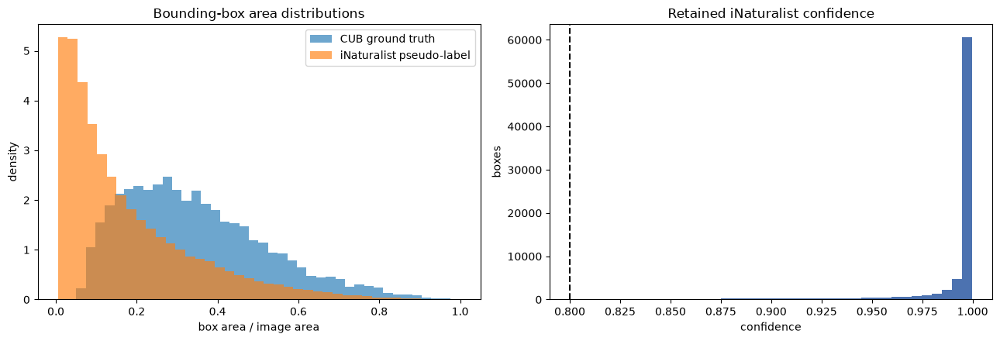

In [23]:
if len(detected):
    cub_area = (
        (cub["_x2"] - cub["_x1"]) * (cub["_y2"] - cub["_y1"])
        / (cub["width_px"] * cub["height_px"])
    )
    detected_area_fraction = (
        detected_dimensions["w"] * detected_dimensions["h"]
        / (detected_dimensions["image_width_px"] * detected_dimensions["image_height_px"])
    )
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    axes[0].hist(cub_area, bins=40, alpha=0.65, density=True, label="CUB ground truth")
    axes[0].hist(detected_area_fraction, bins=40, alpha=0.65, density=True, label="iNaturalist pseudo-label")
    axes[0].set(title="Bounding-box area distributions", xlabel="box area / image area", ylabel="density")
    axes[0].legend()
    axes[1].hist(detected["score"], bins=40, color="#4c72b0")
    axes[1].axvline(DETECTION_SCORE_THRESHOLD, color="black", linestyle="--")
    axes[1].set(title="Retained iNaturalist confidence", xlabel="confidence", ylabel="boxes")
    plt.tight_layout()
    plt.show()

## 10. Visual QA

Saved QA preview: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/previews/inaturalist_multibox_qa_f21df69e17fdf44b.jpg


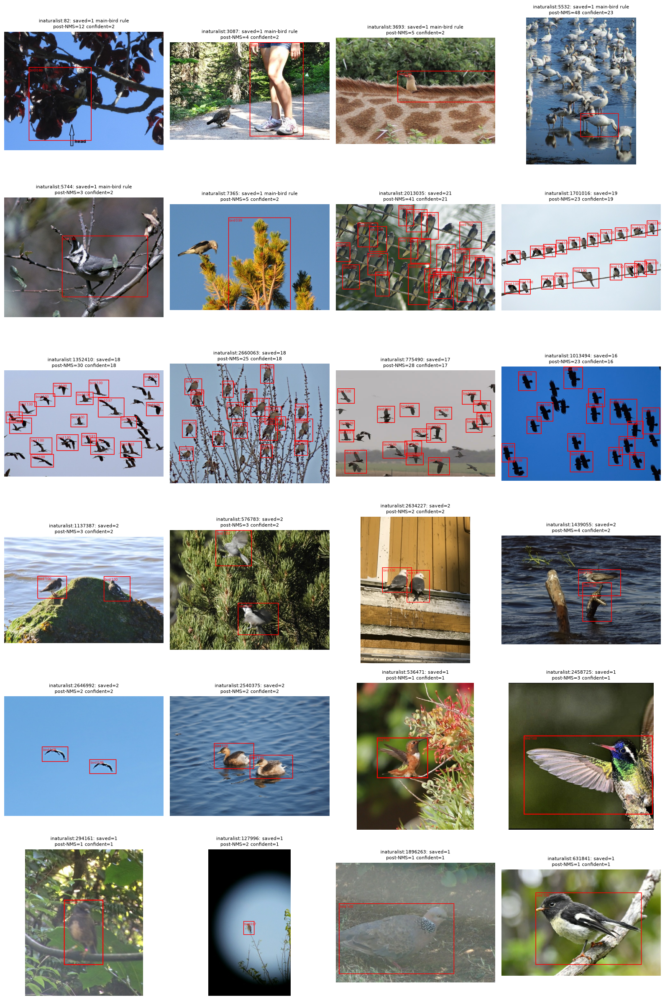

,review_reason,source_id,raw_bird_detection_count,post_nms_detection_count,mixed_rule_candidate_count,qualified_before_mixed_rule_count,saved_detection_count,mixed_size_area_ratio
source_row,,,,,,,,
2,mixed_size_collapsed,inaturalist:82,178,12,2,2,1,4.601546
113,mixed_size_collapsed,inaturalist:3087,88,4,2,2,1,6.320567
129,mixed_size_collapsed,inaturalist:3693,90,5,2,2,1,6.340462
204,mixed_size_collapsed,inaturalist:5532,444,48,23,23,1,5.110189
216,mixed_size_collapsed,inaturalist:5744,122,3,2,2,1,8.466905
316,mixed_size_collapsed,inaturalist:7365,124,5,2,2,1,4.792879
320,mixed_size_collapsed,inaturalist:7402,276,9,4,4,1,5.309095
489,mixed_size_collapsed,inaturalist:12903,130,8,2,2,1,5.265675
803,mixed_size_collapsed,inaturalist:25780,118,3,2,2,1,16.396099


In [24]:
def qa_selection(frame: pd.DataFrame, count: int) -> pd.DataFrame:
    if frame.empty:
        return frame
    candidates = frame.loc[frame["saved_detection_count"].gt(0)].copy()
    if candidates.empty:
        return candidates
    per_group = max(1, count // 4)
    random_sample = candidates.sample(min(per_group, len(candidates)), random_state=SEED)
    selections = [
        candidates.loc[candidates["mixed_size_rule_applied"].astype(bool)].head(per_group),
        candidates.nlargest(per_group, "saved_detection_count"),
        candidates.nsmallest(per_group, "mixed_size_area_ratio", keep="all"),
        random_sample,
    ]
    return pd.concat(selections).drop_duplicates("source_id").head(count)


def render_inaturalist_qa(rows: pd.DataFrame, destination: Path | None = None) -> None:
    if rows.empty:
        print("No images are available for QA")
        return
    columns = 4
    grid_rows = math.ceil(len(rows) / columns)
    fig, axes = plt.subplots(grid_rows, columns, figsize=(16, 4 * grid_rows), squeeze=False)
    source_rows = inat_to_process.set_index("_canonical_source_id")
    records_by_source = prediction_frame.set_index("source_id")
    for ax, row in zip(axes.ravel(), rows.to_dict(orient="records")):
        source_row = source_rows.loc[row["source_id"]]
        record = records_by_source.loc[row["source_id"]]
        image = open_rgb(source_row["_path"])
        draw = ImageDraw.Draw(image)
        line_width = max(2, round(min(image.size) / 150))
        for detection in record["detections"]:
            box = [
                detection["x"], detection["y"],
                detection["x"] + detection["w"], detection["y"] + detection["h"],
            ]
            draw_box(draw, box, "red", f"bird {detection['score']:.2f}", width=line_width)
        ax.imshow(image)
        mixed_label = " main-bird rule" if row["mixed_size_rule_applied"] else ""
        ax.set_title(
            f"{row['source_id']}: saved={row['saved_detection_count']}{mixed_label}\n"
            f"post-NMS={row['post_nms_detection_count']} confident={row['mixed_rule_candidate_count']}",
            fontsize=8,
        )
        ax.axis("off")
    for ax in axes.ravel()[len(rows):]:
        ax.axis("off")
    plt.tight_layout()
    if destination is not None:
        fig.savefig(destination, dpi=140, bbox_inches="tight")
        print(f"Saved QA preview: {destination}")
    plt.show()


if SAVE_QA_PREVIEWS:
    qa_rows = qa_selection(image_audit, QA_PREVIEW_COUNT)
    render_inaturalist_qa(qa_rows, PREVIEW_DIR / f"inaturalist_multibox_qa_{run_signature}.jpg")

review_table = pd.concat(
    {
        "mixed_size_collapsed": image_audit.loc[image_audit["mixed_size_rule_applied"].astype(bool)].head(10),
        "most_saved_boxes": image_audit.nlargest(10, "saved_detection_count"),
        "most_confident_candidates": image_audit.nlargest(10, "mixed_rule_candidate_count"),
        "no_qualifying_box": image_audit.loc[image_audit["status"].eq("no_qualifying_detection")].head(10),
    },
    names=["review_reason", "source_row"],
).reset_index(level=0)
display(
    review_table[
        [
            "review_reason", "source_id", "raw_bird_detection_count",
            "post_nms_detection_count", "mixed_rule_candidate_count",
            "qualified_before_mixed_rule_count", "saved_detection_count", "mixed_size_area_ratio",
        ]
    ]
)

## 11. What to label next

A random sample mostly repeats easy single-bird shots. A random 200 held only a handful
of multi-bird images. This section builds a queue of `LABEL_QUEUE_SIZE` unlabelled
images from the audit, split across these reasons (`LABEL_QUEUE_SHARES`):

| reason | why it helps |
|---|---|
| `mixed_size_rule_fired` | the riskiest heuristic decision: real multi-bird scenes or a false collapse |
| `multiple_confident_birds` | likely multi-bird images, the scarcest kind of label |
| `many_post_nms_candidates` | top 5% by distinct post-NMS candidates: flocks or cluttered scenes. This uses the post-NMS count, not `raw_bird_detection_count`, because with internal NMS off the raw count mostly measures duplicates. |
| `no_qualifying_detection` | missed birds, distant birds, or genuine no-bird images (useful negatives) |
| `uncertain_top_score` | best box scoring 0.2–0.6: the model is unsure |

Images are drawn at random within each reason with a fixed seed. If a reason runs
short, the remainder is filled from the other reasons. Label these in the same tool and
append them to `sampled_manifest_ground_truth.csv`. On the next run they are stratified
into the split, and earlier assignments stay fixed.

These are hard cases. If they land in `gt_select`, held-out metrics will drop because
the set gets harder, not because the model got worse. Compare runs on the original
images when you need a like-for-like comparison.

Labelling queue: /mnt/c/Users/Joe/Desktop/ESP_Classifier/esp32_Classifier/Notebooks/Outputs/iNaturalist Outputs/Bounding Box Outputs/inaturalist_labelling_queue.csv (100 images)


,images
queue_reason,
mixed_size_rule_fired,30
multiple_confident_birds,25
many_post_nms_candidates,15
no_qualifying_detection,15
uncertain_top_score,15


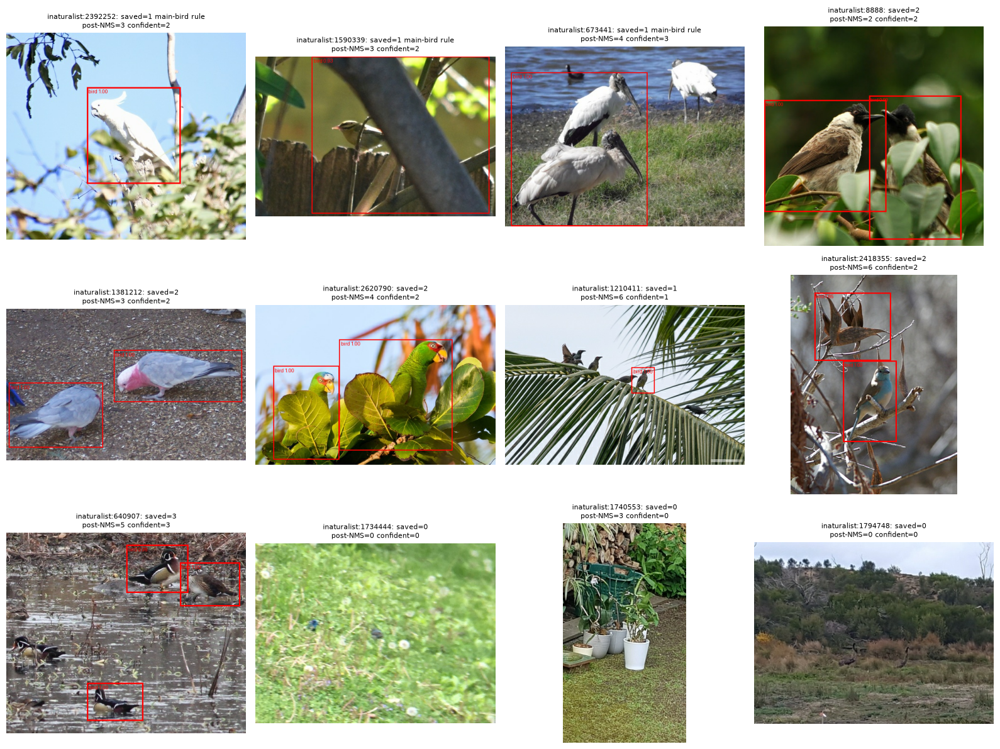

In [25]:
labelled_ids = set(gt_images["source_id"])
pool = image_audit.loc[
    ~image_audit["source_id"].isin(labelled_ids) & image_audit["status"].ne("image_error")
].copy()
post_nms_cutoff = pool["post_nms_detection_count"].quantile(0.95) if len(pool) else math.inf
mixed = pool["mixed_size_rule_applied"].astype(bool)
max_score = pd.to_numeric(pool["max_bird_score"], errors="coerce")
bucket_masks = {
    "mixed_size_rule_fired": mixed,
    "multiple_confident_birds": pool["mixed_rule_candidate_count"].ge(2) & ~mixed,
    "many_post_nms_candidates": pool["post_nms_detection_count"].ge(max(post_nms_cutoff, 2)),
    "no_qualifying_detection": pool["status"].eq("no_qualifying_detection"),
    "uncertain_top_score": max_score.between(0.2, 0.6),
}
if abs(sum(LABEL_QUEUE_SHARES.values()) - 1) > 1e-6 or set(LABEL_QUEUE_SHARES) - set(bucket_masks):
    raise ValueError("LABEL_QUEUE_SHARES must use the bucket names above and sum to 1")

taken: set[str] = set()
queue_parts = []
for position, (reason, share) in enumerate(LABEL_QUEUE_SHARES.items()):
    candidates = pool.loc[bucket_masks[reason] & ~pool["source_id"].isin(taken)]
    quota = int(round(LABEL_QUEUE_SIZE * share))
    picked = candidates.sample(min(quota, len(candidates)), random_state=SEED + position)
    taken.update(picked["source_id"])
    queue_parts.append(picked.assign(queue_reason=reason))
shortfall = LABEL_QUEUE_SIZE - len(taken)
if shortfall > 0:
    any_bucket = np.logical_or.reduce([mask.to_numpy() for mask in bucket_masks.values()])
    leftovers = pool.loc[any_bucket & ~pool["source_id"].isin(taken).to_numpy()]
    filler = leftovers.sample(min(shortfall, len(leftovers)), random_state=SEED + 99)
    reasons = pd.Series("", index=filler.index)
    for reason, mask in bucket_masks.items():
        reasons = reasons.where(reasons.ne("") | ~mask.reindex(filler.index), reason)
    queue_parts.append(filler.assign(queue_reason=reasons + " (top-up)"))

label_queue = pd.concat(queue_parts, ignore_index=True) if queue_parts else pool.head(0)
manifest_columns = ["_canonical_source_id", "_path", *[c for c in RELATIVE_PATH_FIELDS if c in inat_to_process]]
label_queue = label_queue.merge(
    inat_to_process[manifest_columns].rename(columns={"_canonical_source_id": "source_id", "_path": "path"}),
    on="source_id",
    how="left",
)
queue_columns = [
    "source_id", "queue_reason", "path",
    *[c for c in RELATIVE_PATH_FIELDS if c in label_queue],
    "image_width_px", "image_height_px", "saved_detection_count", "mixed_rule_candidate_count",
    "post_nms_detection_count", "max_bird_score", "mixed_size_rule_applied", "status",
]
label_queue = label_queue[queue_columns]
LABEL_QUEUE_CSV = BBOX_OUTPUT_DIR / "inaturalist_labelling_queue.csv"
label_queue.to_csv(LABEL_QUEUE_CSV, index=False, encoding="utf-8-sig")
print(f"Labelling queue: {LABEL_QUEUE_CSV} ({len(label_queue)} images)")
display(label_queue["queue_reason"].value_counts().rename("images").to_frame())

preview = label_queue.groupby("queue_reason", group_keys=False).head(3).head(12)
if len(preview):
    preview_rows = image_audit.set_index("source_id").loc[preview["source_id"]].reset_index()
    render_inaturalist_qa(preview_rows)

## 12. Interpretation and downstream use

* `inaturalist_bird_boxes.csv` is the primary multi-box output and has exactly one
  row per retained box. Images with no qualifying detection get no placeholder row.
* Quote the headline ground-truth split from section 9 (`gt_test`, or `gt_select`
  if there is no test split). `gt_train` numbers are memorised and say nothing about quality.
* The confidence threshold comes from the held-out precision-recall curve (6b), not
  from CUB. Revisit `THRESHOLD_SELECTION_RULE` if downstream training is more hurt by
  false boxes than by missed birds.
* NMS, score and minimum-size filtering operate per box, not per image.
* Similar-sized confident birds are all retained. A largest/smallest area ratio of at
  least 4 among **confident** boxes activates the mixed-size heuristic and keeps only
  the box with the greatest `area × confidence`.
* The detector predicts only a generic `bird` class. The mixed-size rule is a
  conservative proxy and does not truly recognise species or colour.
* **Coordinate space:** boxes are in `summary["coordinate_space"]`. By default that is
  stored pixels with no EXIF rotation. Whatever consumes them, such as crop extraction or
  training the ESP32 classifier, must open images the same way, or rotated photos will
  get misplaced boxes.
* Keep the checkpoint hash, post-processing policy, threshold selection, ground-truth
  split file and run signature with any derived training manifest, so the
  pseudo-labelling run stays reproducible.